<a href="https://colab.research.google.com/github/psh135230-design/BioAI_KU_2026/blob/main/1115_%EB%B0%B1%EC%88%98%ED%98%84.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/psh135230-design/BioAI_KU_2026/blob/main/%EB%B0%94%EC%9D%B4%EC%98%A4%EC%9D%B8%EA%B3%B5%EC%A7%80%EB%8A%A5_10_13(%ED%99%94).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
%pip install -q "scanpy[leiden]==1.11.5" "pandas==2.2.3" "scipy==1.15.3" "scikit-image==0.25.2" tables seaborn


In [ ]:
from google.colab import drive
drive.mount('/content/drive')
DATA = '/content/drive/MyDrive/BioAI_Dataset/'
import os; print(os.listdir(DATA))
import os; print(os.listdir('/content/drive/MyDrive/BioAI_Dataset/'))

In [ ]:
from pathlib import Path
import json, hashlib, re, platform
from importlib.metadata import version
import numpy as np
import pandas as pd
import scanpy as sc
from scipy import sparse
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import adjusted_rand_score
from IPython.display import display

SEED = 0
OUT = Path("mye_results")
OUT.mkdir(exist_ok=True)
sc.settings.figdir = OUT
sc.settings.autoshow = True
versions = {p: version(p) for p in ["scanpy", "anndata", "numpy", "pandas", "scipy", "scikit-learn", "leidenalg", "igraph"]}
print(versions)
(OUT / "versions.json").write_text(json.dumps(versions, indent=2))

def dense(x):
    return x.toarray() if sparse.issparse(x) else np.asarray(x)

def available(panel):
    return {k: keep for k, gs in panel.items() if (keep := [g for g in gs if g in adata.var_names])}

Path("figures_1101").mkdir(exist_ok=True)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)


{'scanpy': '1.11.5', 'anndata': '0.12.19', 'numpy': '2.4.6', 'pandas': '2.2.3', 'scipy': '1.15.3', 'scikit-learn': '1.6.1', 'leidenalg': '0.12.0', 'igraph': '1.0.0'}


In [ ]:
FILE = Path("/content/GSE154763_MYE_count.h5")
if not FILE.exists():
    local = Path("GSE154763_MYE_count.h5")
    if local.exists():
        FILE = local
    else:
        try:
            from google.colab import files
        except ImportError:
            raise FileNotFoundError("GSE154763_MYE_count.h5를 작업 폴더에 넣거나 FILE 경로를 수정하세요.")
        uploaded = files.upload()
        candidates = [Path(name) for name in uploaded if name.endswith(".h5")]
        if len(candidates) != 1:
            raise ValueError("MYE raw count h5 파일 한 개를 업로드하세요.")
        FILE = candidates[0]

raw_adata = sc.read_10x_h5(FILE)
raw_adata.var_names_make_unique()
raw_adata.X = sparse.csr_matrix(raw_adata.X)
v = raw_adata.X.data
if not np.isfinite(v).all() or (v < 0).any() or not np.allclose(v, np.round(v)):
    raise ValueError("입력 파일은 비음수 정수 raw count여야 합니다.")
if not raw_adata.obs_names.is_unique:
    raise ValueError("세포 바코드가 중복됩니다.")
sample = raw_adata.obs_names.to_series().str.extract(r"-(\d+)$", expand=False)
if sample.isna().any():
    raise ValueError("바코드 접미사가 없는 세포가 있습니다. 샘플 대응표가 필요합니다.")
raw_adata.obs["sample"] = sample.astype("category")
raw_adata.var["mt"] = np.asarray(raw_adata.var_names.str.startswith("MT-"), dtype=bool)
sc.pp.calculate_qc_metrics(raw_adata, qc_vars=["mt"], percent_top=None, inplace=True)
print(raw_adata)
display(raw_adata.obs["sample"].value_counts().sort_index())
raw_adata.obs.to_csv(OUT / "input_cell_qc.csv", index_label="cell_barcode")
input_hash = hashlib.sha256("\n".join(raw_adata.obs_names).encode()).hexdigest()

# 이후 원본 셀은 adata라는 이름을 사용합니다.
adata = raw_adata.copy()


AnnData object with n_obs × n_vars = 7619 × 15634
    obs: 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'
    layers: None (.X)


sample
19     360
20    2094
21     750
22    1822
23    1209
24     744
25     640
Name: count, dtype: int64

In [ ]:
print("Data shape:", adata.shape)

print("\nCell metadata:")
print(adata.obs.columns.tolist())

print("\nGene metadata:")
print(adata.var.columns.tolist())

print("\nSaved embeddings:")
print(list(adata.obsm.keys()))

print("\nSaved analyses:")
print(list(adata.uns.keys()))

Data shape: (7619, 15634)

Cell metadata:
['sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt']

Gene metadata:
['gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts']

Saved embeddings:
[]

Saved analyses:
[]


In [ ]:
adata.var_names_make_unique()

# astype(bool)을 추가하여 Pandas BooleanArray 대신 NumPy boolean 배열로 변환하여 저장합니다.
adata.var['mt'] = adata.var_names.str.startswith('MT-').astype(bool)

sc.pp.calculate_qc_metrics(
    adata,
    qc_vars=['mt'],
    percent_top=None,
    inplace=True
)

print(adata.obs[
    ['n_genes_by_counts', 'total_counts', 'pct_counts_mt']
].describe())

       n_genes_by_counts  total_counts  pct_counts_mt
count        7619.000000   7619.000000    7619.000000
mean         1961.669904   6754.211839       3.882464
std           679.841537   4072.257968       1.150013
min           690.000000   2003.000000       0.000000
25%          1447.000000   3987.000000       3.162361
50%          1876.000000   5801.000000       3.732599
75%          2332.000000   8124.500000       4.405609
max          4943.000000  38618.000000       9.976019


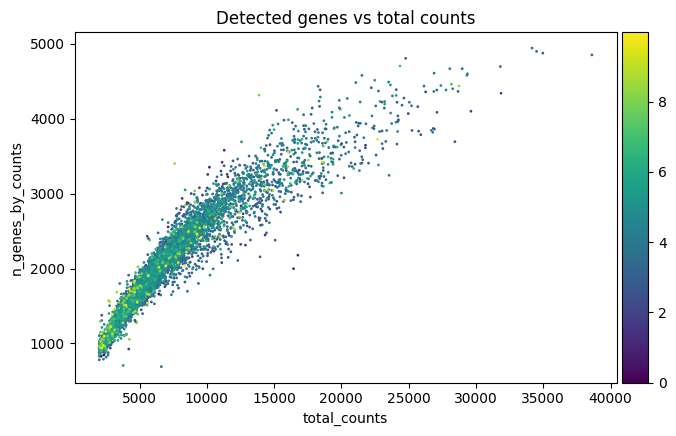

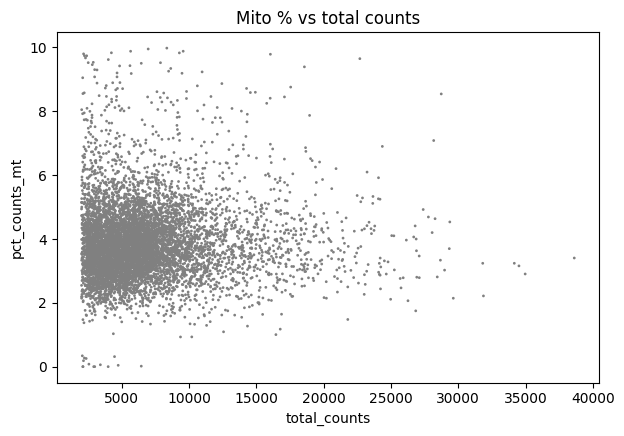

In [ ]:
# 총 count vs 검출 유전자 수 (색 = 미토 비율)
sc.pl.scatter(adata, x='total_counts', y='n_genes_by_counts', color='pct_counts_mt',
              title='Detected genes vs total counts')

# 총 count vs 미토 비율
sc.pl.scatter(adata, x='total_counts', y='pct_counts_mt',
              title='Mito % vs total counts')

In [ ]:
import numpy as np
from scipy import sparse

if sparse.issparse(adata.X):
    values = adata.X.data
else:
    values = np.asarray(adata.X).ravel()

print("Minimum:", values.min())
print("Maximum:", values.max())

# 모든 값이 정수인지 확인
print(
    "Integer counts:",
    np.allclose(values, np.round(values))
)

# 음수 존재 여부
print(
    "Non-negative:",
    np.all(values >= 0)
)

Minimum: 1.0
Maximum: 6140.0
Integer counts: True
Non-negative: True


In [ ]:
# 정규화 재실행 시에도 원본 복사본에서 시작: 이중 정규화 방지
adata = raw_adata.copy()
adata.layers["counts"] = sparse.csr_matrix(raw_adata.X.copy())
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
print(adata)


AnnData object with n_obs × n_vars = 7619 × 15634
    obs: 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'
    uns: 'log1p'
    layers: None (.X), 'counts'


In [ ]:
import numpy as np

# Raw count 데이터
raw_counts = adata.layers["counts"]

# 정규화 및 로그 변환된 데이터
normalized_data = adata.X

print("Raw counts shape:", raw_counts.shape)
print("Normalized data shape:", normalized_data.shape)

print("\nLog transformation 정보:")
print(adata.uns.get("log1p"))

print("\nRaw data:")
print(raw_counts[:5, :5].toarray())

print("\nNormalized & Log-transformed data:")
print(normalized_data[:5, :5].toarray())

Raw counts shape: (7619, 15634)
Normalized data shape: (7619, 15634)

Log transformation 정보:
{'base': None}

Raw data:
[[0. 1. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0.]
 [0. 1. 0. 0. 0.]]

Normalized & Log-transformed data:
[[0.         0.7152578  0.         0.         0.        ]
 [0.         0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.        ]
 [0.         1.11888233 0.         0.         0.        ]
 [0.         0.47150852 0.         0.         0.        ]]


Number of HVGs: 2000


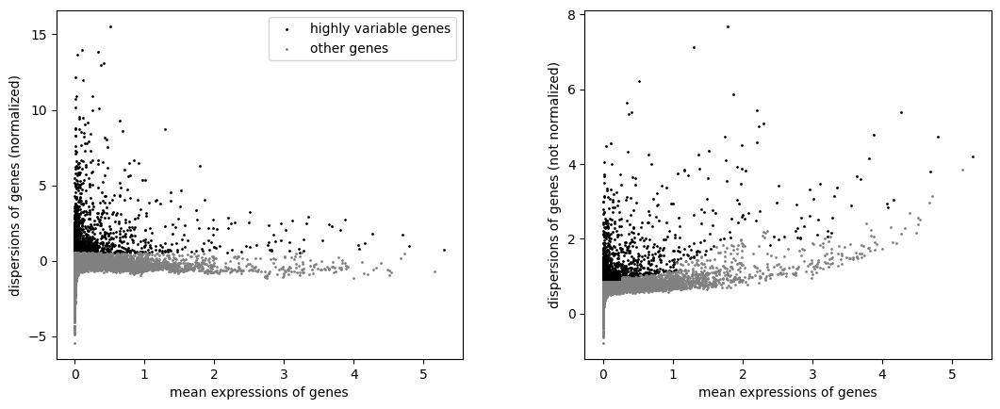

In [ ]:
# HVG 2,000개 선정 (논문에서 STAR methods 분석할 때 HGV 2천 개 선정했다고 했음)
sc.pp.highly_variable_genes(
    adata,
    n_top_genes=2000,
    flavor='seurat'
)

# 선정된 HVG 개수 확인
print(
    "Number of HVGs:",
    adata.var['highly_variable'].sum()
)

# HVG 시각화
sc.pl.highly_variable_genes(adata)

## 3. ARI 비교와 실행 조건 기록
질문: 같은 입력 세포에서 PC 수만 30에서 50으로 바꿨을 때 군집화가 얼마나 달라지는가?
resolution 1.0과 0.6을 각각 별도 비교합니다. 1.0은 PDF 첫 실행의 기본값을 명시한 것이고, 0.6은 기존 최종 주석 설정을 재현하기 위한 것입니다. 이 값들이 최적이라는 뜻은 아닙니다.
PCA는 앞 셀에서 한 번만 계산합니다. 같은 전처리·HVG·PCA의 앞 30/50개를 사용하고, k=15와 seed=0 및 Leiden 구현을 고정합니다. ARI는 대응 라벨로 바꾸지 않고 원래 라벨로 계산합니다. 다른 seed에서의 안정성이나 생물학적 정확도를 검증하는 실험은 아닙니다.


In [ ]:
# PCA를 한 번만 계산하고 PC30/50 비교에서 공유
sc.tl.pca(adata, n_comps=50, mask_var="highly_variable", svd_solver="arpack", random_state=SEED)
# 한 입력 객체에서 그래프를 만들고 결과 라벨을 별도로 보존
if adata.obsm["X_pca"].shape[1] < 50:
    raise ValueError("앞 PCA 셀에서 50개 성분을 먼저 계산하세요.")
if not adata.obs_names.is_unique:
    raise ValueError("입력 바코드가 중복됩니다.")

comparison_index = adata.obs_names.copy()
for pc in [10, 20, 30, 50]:
    sc.pp.neighbors(adata, n_pcs=pc, n_neighbors=15, random_state=SEED,
                    key_added=f"nn{pc}")

# 배열 위치가 아니라 바코드로 연결. 누락/추가/중복은 조용히 제외하지 않고 중단.
def align_partitions(a, b):
    if not a.index.is_unique or not b.index.is_unique:
        raise ValueError("군집 결과에 중복 바코드가 있습니다.")
    if a.isna().any() or b.isna().any():
        raise ValueError("군집 라벨에 누락값이 있습니다.")
    if len(a.index.difference(b.index)) or len(b.index.difference(a.index)):
        raise ValueError("두 군집 결과의 세포 집합이 다릅니다.")
    b = b.reindex(a.index)
    assert a.index.equals(b.index)
    return a.astype(str), b.astype(str)

runs, partitions = [], {}
for resolution, tag, pcs in [(1.0, "res10", [10,20,30,50]),
                             (0.6, "res06", [30,50])]:
    for pc in pcs:
        key = f"leiden_pc{pc}_{tag}"
        sc.tl.leiden(adata, neighbors_key=f"nn{pc}", resolution=resolution,
                     random_state=SEED, flavor="leidenalg", n_iterations=-1,
                     directed=True, use_weights=True, key_added=key)
        labels = adata.obs[key].copy()
        if not labels.index.equals(comparison_index):
            raise ValueError("실행 중 세포 순서가 달라졌습니다.")
        partitions[key] = labels
        labels.to_csv(OUT / f"{key}_labels.csv", index_label="cell_barcode")
        runs.append({"run":key, "n_cells":adata.n_obs,
                     "cell_order_sha256":input_hash, "n_pcs":pc,
                     "n_neighbors":15, "resolution":resolution, "seed":SEED,
                     "leiden_flavor":"leidenalg", "directed":True,
                     "use_weights":True, "n_iterations":-1,
                     "n_clusters":labels.nunique(), "batch_correction":False,
                     "input":"same log1p matrix / HVG2000 / one PCA50",
                     "code_location":"section 3 ARI comparison cell"})

run_table = pd.DataFrame(runs)
run_table.to_csv(OUT / "clustering_run_conditions.csv", index=False)
ari_rows = []
for tag in ["res10", "res06"]:
    ka, kb = f"leiden_pc30_{tag}", f"leiden_pc50_{tag}"
    a, b = align_partitions(partitions[ka], partitions[kb])
    value = adjusted_rand_score(a, b)
    ari_rows.append({"comparison":tag, "label_a":ka, "label_b":kb,
                     "n_cells":len(a), "ARI":value,
                     "clusters_pc30":a.nunique(), "clusters_pc50":b.nunique(),
                     "cell_set_match":True, "order_aligned_by_barcode":True})
ari_table = pd.DataFrame(ari_rows)
ari_table.to_csv(OUT / "ari_comparisons.csv", index=False)
print(run_table.drop(columns=["cell_order_sha256"]).to_string(index=False))
print(ari_table.to_string(index=False))
# 0.82 / 0.834는 과거 출력입니다. 새 값을 강제하지 않습니다.
adata.obs["leiden_30"] = adata.obs["leiden_pc30_res06"].copy()
adata.obs["leiden_50"] = adata.obs["leiden_pc50_res06"].copy()
sc.tl.umap(adata, neighbors_key="nn30", random_state=SEED)


/tmp/ipykernel_1508/3207298720.py:31: UserWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
  sc.tl.leiden(adata, neighbors_key=f"nn{pc}", resolution=resolution,
/tmp/ipykernel_1508/3207298720.py:31: UserWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
  sc.tl.leiden(adata, neighbors_key=f"nn{pc}", resolution=resolution,
/tmp/ipykernel_1508/3207298720.py:31: UserWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
  sc.tl.leiden(adata, neighbors_key=f"nn{pc}", resolution=resolution,
/tmp/ipykernel_1508/3207298720.py:31: UserWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if ne

              run  n_cells  n_pcs  n_neighbors  resolution  seed leiden_flavor  directed  use_weights  n_iterations  n_clusters  batch_correction                                   input                 code_location
leiden_pc10_res10     7619     10           15         1.0     0     leidenalg      True         True            -1          19             False same log1p matrix / HVG2000 / one PCA50 section 3 ARI comparison cell
leiden_pc20_res10     7619     20           15         1.0     0     leidenalg      True         True            -1          17             False same log1p matrix / HVG2000 / one PCA50 section 3 ARI comparison cell
leiden_pc30_res10     7619     30           15         1.0     0     leidenalg      True         True            -1          18             False same log1p matrix / HVG2000 / one PCA50 section 3 ARI comparison cell
leiden_pc50_res10     7619     50           15         1.0     0     leidenalg      True         True            -1          18         

## 4. 667개 산출 규칙과 분할·병합 점검
기존 규칙 보존: PC30의 각 군집에서 가장 많은 세포가 이동한 PC50 군집을 대표 대응으로 정합니다. 그 대표 대응 밖의 세포 수를 셉니다. 동률이면 숫자가 작은 라벨을 선택하고 동률 여부를 표에 남깁니다. 동률 시 대응 선택은 임의적이라는 한계가 있습니다.
이 규칙은 PC30 기준의 방향성 있는 요약이며 일대일 대응이 아닙니다. 순수 병합은 변경 0개로 계산될 수 있습니다. 따라서 667개를 전체 구조 변화에 관여한 세포 수로 해석하지 않습니다.
역방향 최빈 대응과 각 행/열의 전체 구성도 함께 저장합니다. 역방향 수치를 새로운 정답으로 사용하거나 두 방향을 합쳐 전체 변경 수로 부르지 않습니다. ARI는 이 대응 규칙과 독립적으로 계산됩니다.


In [ ]:
def numeric_order(values):
    return sorted(set(map(str, values)), key=lambda s: int(s))

# 계산 규칙을 함수로 분리하여 실제 데이터와 작은 반례에 동일하게 적용
def modal_correspondence(a, b):
    a, b = align_partitions(a, b)
    # Pandas 2.2.x의 crosstab/unstack 버그 우회를 위해 직접 빈도 행렬 생성
    df_temp = pd.DataFrame({'a': a, 'b': b})
    group_sizes = df_temp.groupby(['a', 'b'], observed=False).size()

    # 재인덱싱할 크기 설정
    row_order = numeric_order(a)
    col_order = numeric_order(b)

    # 2D dict/array를 구성하여 table 생성 (unstack() 버그 완벽 회피)
    table_data = {col: [group_sizes.get((row, col), 0) for row in row_order] for col in col_order}
    table = pd.DataFrame(table_data, index=row_order)

    forward = table.idxmax(axis=1)  # 숫자 오름차순으로 정렬 후 동률 첫 값
    reverse = table.idxmax(axis=0)
    frame = pd.DataFrame({"pc30":a, "pc50":b})
    frame["pc50_modal_from_pc30"] = frame["pc30"].map(forward)
    frame["pc30_modal_from_pc50"] = frame["pc50"].map(reverse)
    frame["off_pc30_modal"] = frame["pc50"].ne(frame["pc50_modal_from_pc30"])
    frame["off_pc50_modal"] = frame["pc30"].ne(frame["pc30_modal_from_pc50"])
    row = pd.DataFrame({"pc50_modal_label":forward, "n_cells":table.sum(axis=1),
                        "n_modal":table.max(axis=1),
                        "n_tied_maxima":table.eq(table.max(axis=1), axis=0).sum(axis=1),
                        "n_pc50_destinations":table.gt(0).sum(axis=1)})
    row["n_off_modal"] = row["n_cells"] - row["n_modal"]
    row["off_modal_percent"] = row["n_off_modal"] / row["n_cells"] * 100
    column = pd.DataFrame({"pc30_modal_label":reverse, "n_cells":table.sum(axis=0),
                           "n_modal":table.max(axis=0),
                           "n_tied_maxima":table.eq(table.max(axis=0), axis=1).sum(axis=0),
                           "n_pc30_sources":table.gt(0).sum(axis=0)})
    column["n_off_modal"] = column["n_cells"] - column["n_modal"]
    return table, frame, row, column

# 의미가 알려진 작은 사례: 번호 치환, 병합, 분할, 순서 재정렬
idx = pd.Index(["cell_a","cell_b","cell_c","cell_d"])
a_test = pd.Series(["0","0","1","1"], index=idx)
renamed = pd.Series(["8","8","9","9"], index=idx)
assert adjusted_rand_score(*align_partitions(a_test, renamed.iloc[::-1])) == 1
assert modal_correspondence(a_test, renamed)[1]["off_pc30_modal"].sum() == 0
merged = pd.Series(["0","0","0","0"], index=idx)
assert modal_correspondence(a_test, merged)[1]["off_pc30_modal"].sum() == 0
assert adjusted_rand_score(a_test, merged) < 1
split = pd.Series(["0","1","2","2"], index=idx)
assert modal_correspondence(a_test, split)[1]["off_pc30_modal"].sum() == 1
print("규칙 확인 통과: 순서 재정렬 / 라벨 치환 / 병합의 사각지대 / 분할")

ct, cell_map, mapping, reverse_mapping = modal_correspondence(
    adata.obs["leiden_30"], adata.obs["leiden_50"])
cell_map.insert(0, "sample", adata.obs["sample"].reindex(cell_map.index))
changed = cell_map["off_pc30_modal"].reindex(adata.obs_names)
adata.obs["changed"] = pd.Categorical(np.where(changed,"changed","same"), categories=["changed","same"])
adata.uns["changed_colors"] = ["red","lightgrey"]
order30, order50 = ct.index.tolist(), ct.columns.tolist()
ct.to_csv(OUT / "pc30_pc50_full_contingency.csv")
ct.div(ct.sum(axis=1),axis=0).to_csv(OUT / "pc30_pc50_row_fractions.csv")
ct.div(ct.sum(axis=0),axis=1).to_csv(OUT / "pc30_pc50_column_fractions.csv")
mapping.to_csv(OUT / "cluster_mapping_rule.csv")
reverse_mapping.to_csv(OUT / "reverse_cluster_mapping.csv")
cell_map.to_csv(OUT / "cell_correspondence.csv", index_label="cell_barcode")
counts = pd.DataFrame([{"direction":"PC30 to PC50", "n_off_modal":int(changed.sum()),
                        "percent":float(changed.mean()*100)},
                       {"direction":"PC50 to PC30", "n_off_modal":int(cell_map["off_pc50_modal"].sum()),
                        "percent":float(cell_map["off_pc50_modal"].mean()*100)}])
counts.to_csv(OUT / "directional_off_modal_counts.csv",index=False)
print(counts.to_string(index=False))
print(mapping.to_string())
print(reverse_mapping.to_string())
print("과거 667개와의 일치는 실행 결과로 확인합니다. 값을 강제하지 않습니다.")

규칙 확인 통과: 순서 재정렬 / 라벨 치환 / 병합의 사각지대 / 분할
   direction  n_off_modal  percent
PC30 to PC50          667 8.754430
PC50 to PC30          584 7.665048
   pc50_modal_label  n_cells  n_modal  n_tied_maxima  n_pc50_destinations  n_off_modal  off_modal_percent
0                 0     1524     1470              1                    6           54           3.543307
1                 2     1188      893              1                    7          295          24.831650
2                 1      878      874              1                    2            4           0.455581
3                 3      640      572              1                    4           68          10.625000
4                 4      621      539              1                    7           82          13.204509
5                 5      565      537              1                    8           28           4.955752
6                 6      545      544              1                    2            1           0.183486
7     

/tmp/ipykernel_1508/3107958197.py:36: Pandas4Warning: The copy keyword is deprecated and will be removed in a future version. Copy-on-Write is active in pandas since 3.0 which utilizes a lazy copy mechanism that defers copies until necessary. Use .copy() to make an eager copy if necessary.
  comp.plot(kind='barh', stacked=True, ax=ax[1, 0], colormap='tab10', legend=False)


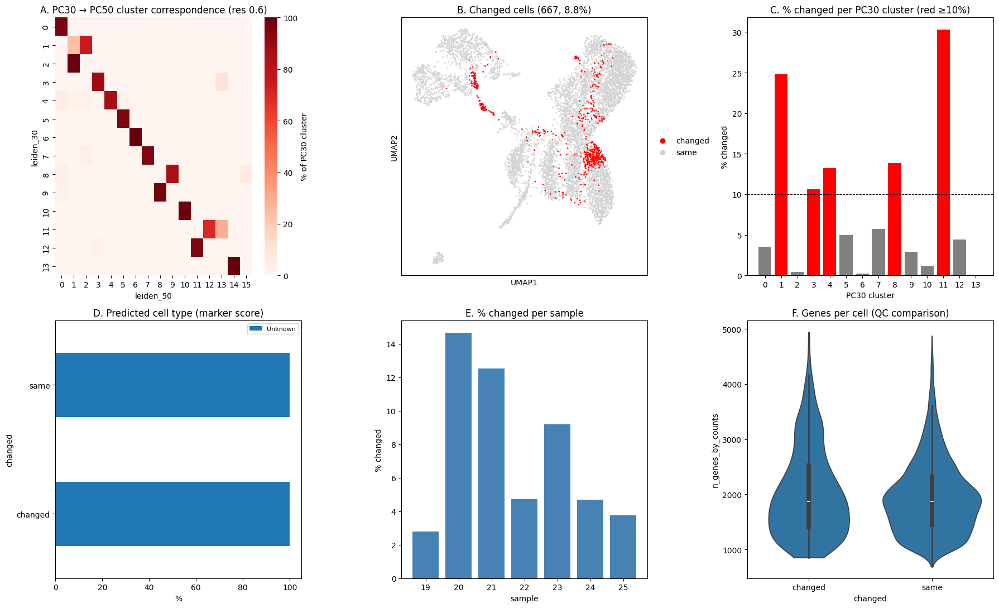

[A] 행별 집중도는 PC30 군집의 주 대응을 보여줌. 병합은 열별 구성도 함께 확인해야 함.
[B] 전체 7619개 중 667개(8.8%)가 바뀌었음. 빨간 점은 PC30 기준 최빈 대응 밖의 세포이며 생물학적 경계를 확정하지 않음.
[C] 변경 비율 10% 이상 군집: 11(30%), 1(25%), 8(14%), 4(13%), 3(11%).
[D] 바뀐 세포 세포형: Unknown 100.0%(그대로 100.0%).
[E] 샘플별 변경 비율은 2.8~14.7%이고, 가장 높은 샘플은 20임.
[F] 유전자 수 중앙값은 바뀐 세포 1875, 그대로 1876임. 이 중앙값 비교만으로 doublet을 배제할 수 없음.
※ 세포형은 마커 점수로 추정한 값이라 확정 주석이 아님.


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# 'pred_type' 컬럼이 없는 경우에 대비한 안전 장치 추가
if 'pred_type' not in adata.obs:
    if 'MajorCluster' in adata.obs:
        adata.obs['pred_type'] = adata.obs['MajorCluster'].copy()
    else:
        adata.obs['pred_type'] = 'Unknown'

obs = adata.obs
order30 = sorted(obs['leiden_30'].unique(), key=int)
fig, ax = plt.subplots(2, 3, figsize=(18, 11))

# A. 교차표 히트맵 (행 = PC30 군집, 각 행을 100%로) - unstack 버그 우회
grp_a = obs.groupby(['leiden_30', 'leiden_50'], observed=False).size().unstack(fill_value=0)
ct = grp_a.div(grp_a.sum(axis=1), axis=0) * 100
sns.heatmap(ct.loc[order30], cmap='Reds', vmin=0, vmax=100, ax=ax[0, 0], cbar_kws={'label': '% of PC30 cluster'})
ax[0, 0].set_title('A. PC30 → PC50 cluster correspondence (res 0.6)')

# B. UMAP: 바뀐 세포
sc.pl.umap(adata, color='changed', palette=['red', 'lightgrey'], ax=ax[0, 1], show=False,
           title=f"B. Changed cells ({(obs['changed']=='changed').sum()}, {(obs['changed']=='changed').mean()*100:.1f}%)")

# C. 군집별 변경 비율
rate = obs.groupby('leiden_30', observed=True)['changed'].apply(lambda x: (x == 'changed').mean() * 100).loc[order30]
ax[0, 2].bar(rate.index.astype(str), rate.values, color=['red' if v >= 10 else 'grey' for v in rate.values])
ax[0, 2].axhline(10, ls='--', c='k', lw=0.8)
ax[0, 2].set(title='C. % changed per PC30 cluster (red ≥10%)', xlabel='PC30 cluster', ylabel='% changed')

# D. 세포형 구성: 바뀐 vs 그대로 - unstack 버그 우회
grp_d = obs.groupby(['changed', 'pred_type'], observed=False).size().unstack(fill_value=0)
comp = grp_d.div(grp_d.sum(axis=1), axis=0) * 100
comp.plot(kind='barh', stacked=True, ax=ax[1, 0], colormap='tab10', legend=False)
ax[1, 0].set(title='D. Predicted cell type (marker score)', xlabel='%')
ax[1, 0].legend(bbox_to_anchor=(1, 1), fontsize=8)

# E. 샘플별 변경 비율
srate = obs.groupby('sample', observed=True)['changed'].apply(lambda x: (x == 'changed').mean() * 100)
ax[1, 1].bar(srate.index.astype(str), srate.values, color='steelblue')
ax[1, 1].set(title='E. % changed per sample', xlabel='sample', ylabel='% changed')

# F. QC 비교
sns.violinplot(data=obs, x='changed', y='n_genes_by_counts', ax=ax[1, 2], cut=0)
ax[1, 2].set(title='F. Genes per cell (QC comparison)')

plt.tight_layout()
plt.savefig('figures_1101/F_changed_summary_res06.png', dpi=200, bbox_inches='tight')
plt.show()

# ===== 자동 해설 =====
n_ch = (obs['changed'] == 'changed').sum()
hi = rate[rate >= 10]
c_comp = comp.reindex(["changed", "same"], fill_value=0).loc['changed'].sort_values(ascending=False)
s_comp = comp.reindex(['changed', 'same'], fill_value=0).loc['same']
med = obs.groupby('changed', observed=True)['n_genes_by_counts'].median()
print("[A] 행별 집중도는 PC30 군집의 주 대응을 보여줌. 병합은 열별 구성도 함께 확인해야 함.")
print(f"[B] 전체 {len(obs)}개 중 {n_ch}개({n_ch/len(obs)*100:.1f}%)가 바뀌었음. 빨간 점은 PC30 기준 최빈 대응 밖의 세포이며 생물학적 경계를 확정하지 않음.")
print(f"[C] 변경 비율 10% 이상 군집: " + ', '.join(f"{k}({v:.0f}%)" for k, v in hi.sort_values(ascending=False).items()) + ".")
print("[D] 바뀐 세포 세포형: " + ', '.join(f"{k} {v:.1f}%(그대로 {s_comp[k]:.1f}%)" for k, v in c_comp.head(4).items()) + ".")
print(f"[E] 샘플별 변경 비율은 {srate.min():.1f}~{srate.max():.1f}%이고, 가장 높은 샘플은 {srate.idxmax()}임.")
print(f"[F] 유전자 수 중앙값은 바뀐 세포 {med['changed']:.0f}, 그대로 {med['same']:.0f}임. 이 중앙값 비교만으로 doublet을 배제할 수 없음.")
print("※ 세포형은 마커 점수로 추정한 값이라 확정 주석이 아님.")

PCA shape: (7619, 50)


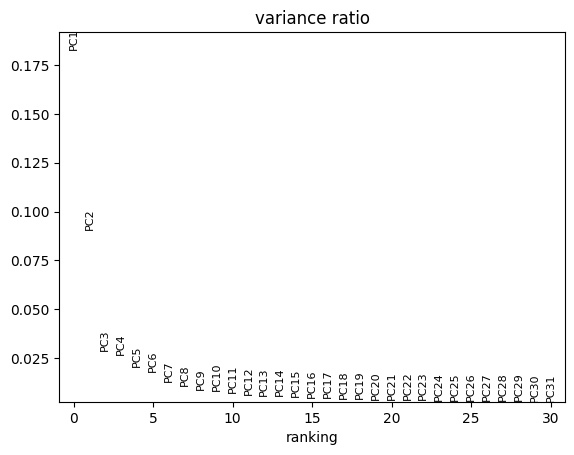

,주성분 (PC),설명 분산 비율 (%),누적 설명 분산 비율 (%)
0,PC1,18.28,18.28
1,PC2,9.05,27.33
2,PC3,2.86,30.19
3,PC4,2.68,32.87
4,PC5,2.04,34.91


In [ ]:
# 앞서 계산한 PCA50을 유지하고 첫 30개 성분의 설명력을 확인합니다.
# PCA 결과 확인
print("PCA shape:", adata.obsm['X_pca'].shape)


# 설명 분산 비율 시각화
sc.pl.pca_variance_ratio(
    adata,
    n_pcs=30,
    log=False
)

variance_ratio = adata.uns["pca"]["variance_ratio"][:5]
pcs = [f"PC{i+1}" for i in range(len(variance_ratio))]
explained_pct = variance_ratio * 100
cumulative_pct = np.cumsum(explained_pct)

pca_summary_df = pd.DataFrame(
    {
        "주성분 (PC)": pcs,
        "설명 분산 비율 (%)": np.round(explained_pct, 2),
        "누적 설명 분산 비율 (%)": np.round(cumulative_pct, 2),
    }
)

# 표 출력
pd.set_option("display.max_rows", 30)
display(pca_summary_df)

In [ ]:
import numpy as np, pandas as pd, scanpy as sc, matplotlib.pyplot as plt

# 'leiden' 대신 정의된 'leiden_30' 컬럼의 고유 클러스터 개수를 출력합니다.
if 'leiden_30' in adata.obs:
    print(f"leiden_30 클러스터 개수: {adata.obs['leiden_30'].nunique()}개 (기존 실행은 14개; 새 결과를 강제하지 않음)")
elif 'leiden' in adata.obs:
    print(f"leiden 클러스터 개수: {adata.obs['leiden'].nunique()}개")
else:
    print("경고: 'leiden_30' 또는 'leiden' 클러스터 정보가 adata.obs에 없습니다.")

print("'counts' 레이어 보존 여부:", 'counts' in adata.layers)
# 'counts'가 없는(False) 경우: 노트북 맨 위 normalize_total 직전에 adata.layers['counts'] = adata.X.copy() 넣고 다시 실행

leiden_30 클러스터 개수: 14개 (기존 실행은 14개; 새 결과를 강제하지 않음)
'counts' 레이어 보존 여부: True


/tmp/ipykernel_1508/2265945674.py:17: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.dotplot(adata, plot_markers, groupby='leiden_30', standard_scale='var', cmap='Reds',


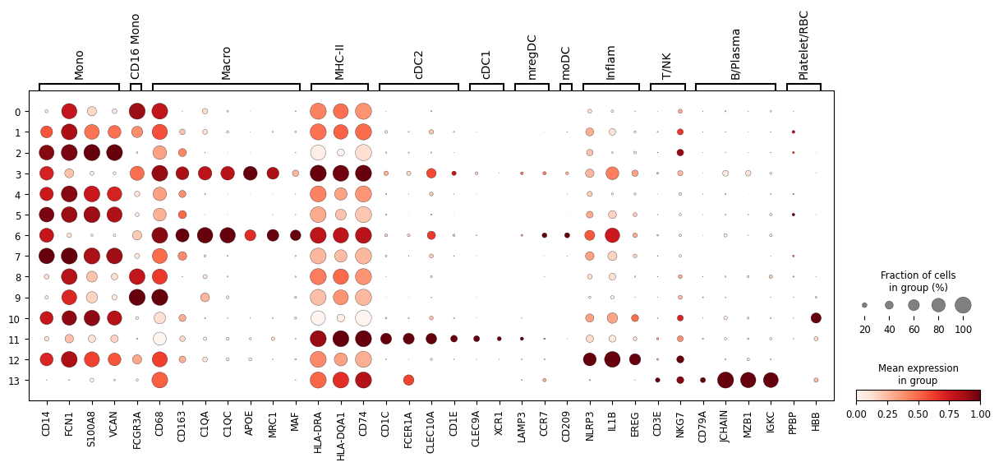

    C1QC  APOE  MRC1  CD163  CD1C  FCER1A  CLEC10A  CLEC9A  JCHAIN  MZB1
3   80.0  82.0  67.0   75.0  18.0    17.0     50.0    10.0    26.0  24.0
6   94.0  61.0  66.0   77.0  10.0     9.0     41.0     2.0    12.0   1.0
11  10.0   7.0  13.0   24.0  60.0    60.0     58.0    26.0     7.0   5.0


In [ ]:
markers = {
    'Mono':      ['CD14', 'FCN1', 'S100A8', 'VCAN'],
    'CD16 Mono': ['FCGR3A'],
    'Macro':     ['CD68', 'CD163', 'C1QA', 'C1QC', 'APOE', 'MRC1', 'MAF'],
    'MHC-II':    ['HLA-DRA', 'HLA-DQA1', 'CD74'],
    'cDC2':      ['CD1C', 'FCER1A', 'CLEC10A', 'CD1E'],
    'cDC1':      ['CLEC9A', 'XCR1'],
    'mregDC':    ['LAMP3', 'CCR7'],
    'moDC':      ['CD209'],
    'Inflam':    ['NLRP3', 'IL1B', 'EREG'],
    'T/NK':      ['CD3E', 'NKG7'],
    'B/Plasma':  ['CD79A', 'JCHAIN', 'MZB1', 'IGKC'],
    'Platelet/RBC': ['PPBP', 'HBB'],
}
# groupby 컬럼을 기존 'leiden'에서 실제 존재하는 'leiden_30'으로 변경합니다.
plot_markers = available(markers)
sc.pl.dotplot(adata, plot_markers, groupby='leiden_30', standard_scale='var', cmap='Reds',
              save='_F3_ambiguous_multimarker.png')

# 군집 3, 6, 11의 발현 세포 비율(%) 표로 확인 (leiden -> leiden_30)
genes = ['C1QC','APOE','MRC1','CD163','CD1C','FCER1A','CLEC10A','CLEC9A','JCHAIN','MZB1']
genes = [g for g in genes if g in adata.var_names]
sub = adata[adata.obs['leiden_30'].isin(['3','6','11']), genes]
pct = pd.DataFrame((sub.X > 0).toarray() if hasattr(sub.X,'toarray') else (sub.X > 0),
                   columns=genes, index=sub.obs_names).groupby(sub.obs['leiden_30'].values).mean()*100
print(pct.round(0))

## 7. 다중 마커와 군집 11의 같은 세포 내 발현
raw count > 0을 검출 기준으로 사용합니다. 동시 검출은 기능적 정체성이나 doublet 여부를 단독으로 확정하지 않습니다. 군집 번호가 기존과 달라지면 마커를 보고 TARGET_CLUSTER를 변경하세요.


In [ ]:
TARGET_CLUSTER="11"
co_genes=["CD1C","FCER1A","CLEC9A","XCR1"]
missing=[x for x in co_genes if x not in adata.var_names]
print("미검출 유전자(행렬에 없음):",missing)
mask=adata.obs["leiden_30"].astype(str).eq(TARGET_CLUSTER)
if mask.any() and all(x in adata.var_names for x in ["CD1C","CLEC9A"]):
    sub=adata[mask]
    genes=[x for x in co_genes if x in adata.var_names]
    per_cell=pd.DataFrame(dense(sub[:,genes].layers["counts"]),index=sub.obs_names,columns=genes)
    per_cell["sample"]=sub.obs["sample"]
    a,b=per_cell["CD1C"]>0,per_cell["CLEC9A"]>0
    per_cell["detection_group"]=np.select([a&b,a&~b,~a&b],["both","CD1C_only","CLEC9A_only"],default="neither")
    per_cell.to_csv(OUT / "cluster11_coexpression_by_cell.csv",index_label="cell_barcode")
    tab=per_cell["detection_group"].value_counts().reindex(["both","CD1C_only","CLEC9A_only","neither"],fill_value=0).to_frame("n_cells")
    tab["percent"]=tab["n_cells"]/len(per_cell)*100
    tab.to_csv(OUT / "cluster11_coexpression_summary.csv"); display(tab)

    # pd.crosstab() 대신 Pandas 2.2.3 unstack 버그를 완전히 우회하는 수동 그룹화 테이블 생성 및 표시
    crosstab_alternative = per_cell.groupby(["sample", "detection_group"], observed=False).size().unstack(fill_value=0)
    display(crosstab_alternative)
else:
    print("대상 군집 또는 필수 유전자가 없어 동시 발현 계산을 생략합니다.")

미검출 유전자(행렬에 없음): []


,n_cells,percent
detection_group,,
both,3,1.714286
CD1C_only,102,58.285714
CLEC9A_only,43,24.571429
neither,27,15.428571


detection_group,CD1C_only,CLEC9A_only,both,neither
sample,,,,
19,23,7,0,10
20,25,1,0,3
21,2,17,2,0
22,14,0,0,3
23,3,0,0,3
24,28,0,0,4
25,7,18,1,4


## 5. 샘플별 Scrublet
raw count 전체 유전자를 사용합니다. 추정 샘플별로 점수·자동 임계값을 계산하며 임계값을 강제로 조정하지 않습니다. 같은 계열 doublet이나 RNA 혼입을 이 결과만으로 배제하지 않습니다.


전체 예측 doublet: 65 / 7619
전체 예측 비율(%): 0.8531303320645753
        n_cells  n_predicted  predicted_fraction  max_score  threshold  predicted_percent
sample                                                                                   
19          360            2            0.005556   0.185714   0.163373           0.555556
20         2094           11            0.005253   0.475862   0.342877           0.525310
21          750            7            0.009333   0.355932   0.246480           0.933333
22         1822           15            0.008233   0.453237   0.319885           0.823271
23         1209            5            0.004136   0.401575   0.274237           0.413565
24          744           14            0.018817   0.355932   0.218020           1.881720
25          640           11            0.017188   0.339130   0.223263           1.718750


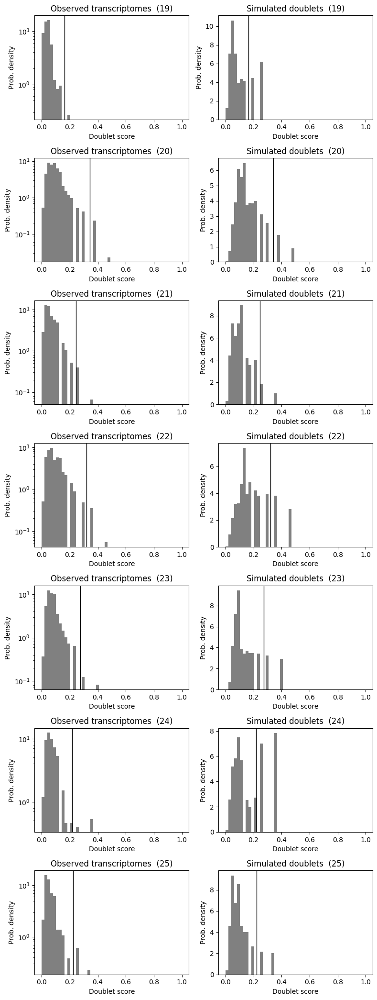

,total_counts,n_genes_by_counts,pct_counts_mt,doublet_score,predicted_doublet_percent,Ig_above_1_percent_cells
leiden_30,,,,,,
0,5854.5,1876.0,3.789634,0.087479,0.853018,0.656168
1,6345.0,2035.0,3.764970,0.096774,0.841751,0.252525
2,4661.5,1613.0,3.805966,0.071913,0.341686,0.113895
3,12602.0,2870.5,4.145480,0.059048,1.093750,15.468750
4,3865.0,1418.0,3.837118,0.064295,0.483092,0.000000
5,3513.0,1338.0,3.282921,0.064295,0.353982,0.353982
6,6105.0,1827.0,3.572133,0.053640,1.834862,0.366972
7,5968.5,2022.0,3.914040,0.065574,1.535088,0.000000
8,5702.0,1818.0,3.297066,0.087479,1.067616,6.405694


/tmp/ipykernel_1508/3937078519.py:33: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.violin(adata,["total_counts","n_genes_by_counts","pct_counts_mt","doublet_score","pct_ig"],


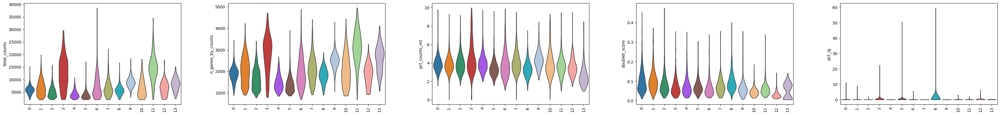

sample,19,20,21,22,23,24,25
leiden_30,,,,,,,
0,2,13,0,1138,358,13,0
1,0,1158,5,9,11,5,0
2,4,860,3,9,2,0,0
3,1,0,631,0,0,0,8
4,1,18,0,543,57,1,1
5,4,0,0,41,517,3,0
6,0,0,8,0,0,0,537
7,0,0,0,3,5,446,2
8,3,1,0,39,237,1,0


/tmp/ipykernel_1508/3937078519.py:39: Pandas4Warning: The copy keyword is deprecated and will be removed in a future version. Copy-on-Write is active in pandas since 3.0 which utilizes a lazy copy mechanism that defers copies until necessary. Use .copy() to make an eager copy if necessary.
  composition.div(composition.sum(axis=1),axis=0).plot.bar(stacked=True,figsize=(10,4))


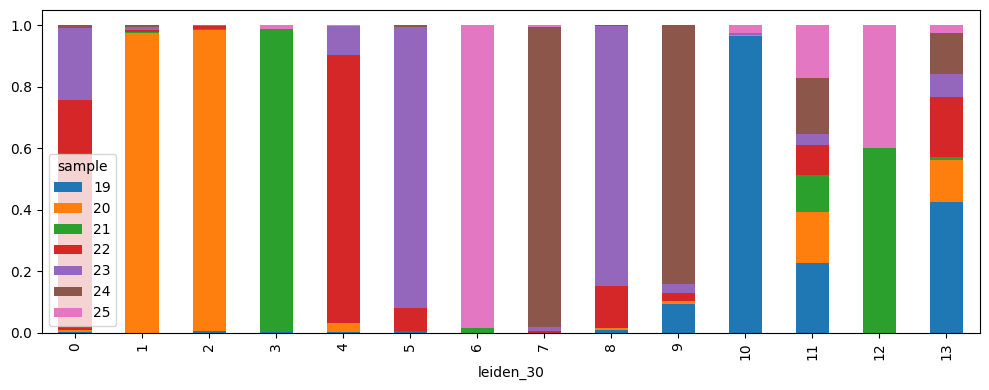

XIST {'0': 0.0032808398950131233, '1': 0.0025252525252525255, '2': 0.0, '3': 0.0015625, '4': 0.001610305958132045, '5': 0.0, '6': 0.48440366972477067, '7': 0.5219298245614035, '8': 0.0035587188612099642, '9': 0.3442028985507246, '10': 0.019762845849802372, '11': 0.13714285714285715, '12': 0.1925925925925926, '13': 0.0975609756097561}
DDX3Y {'0': 0.11548556430446194, '1': 0.2138047138047138, '2': 0.14578587699316628, '3': 0.515625, '4': 0.11755233494363929, '5': 0.1504424778761062, '6': 0.012844036697247707, '7': 0.0043859649122807015, '8': 0.18149466192170818, '9': 0.028985507246376812, '10': 0.23715415019762845, '11': 0.2571428571428571, '12': 0.26666666666666666, '13': 0.17073170731707318}
RPS4Y1 {'0': 0.8943569553805775, '1': 0.9191919191919192, '2': 0.9191343963553531, '3': 0.9078125, '4': 0.8454106280193237, '5': 0.7964601769911505, '6': 0.012844036697247707, '7': 0.015350877192982455, '8': 0.8932384341637011, '9': 0.12318840579710146, '10': 0.7351778656126482, '11': 0.58285714285

In [ ]:
# csr_array의 메서드를 전역 패치하지 않고 입력을 csr_matrix로 명시합니다.
scrub = sc.AnnData(X=sparse.csr_matrix(raw_adata.X.copy()),
                   obs=raw_adata.obs[["sample"]].copy(),var=raw_adata.var.copy())
sc.pp.scrublet(scrub,batch_key="sample",random_state=SEED,expected_doublet_rate=0.05,
               sim_doublet_ratio=2.0)
for col in ["doublet_score","predicted_doublet"]:
    adata.obs[col]=scrub.obs[col].reindex(adata.obs_names)
if adata.obs[["doublet_score","predicted_doublet"]].isna().any().any():
    raise ValueError("Scrublet 결과에 누락값이 있습니다.")
summary=scrub.obs.groupby("sample",observed=True).agg(
    n_cells=("doublet_score","size"),n_predicted=("predicted_doublet","sum"),
    predicted_fraction=("predicted_doublet","mean"),max_score=("doublet_score","max"))
batches=scrub.uns["scrublet"]["batches"]
summary["threshold"]=[batches[str(s)].get("threshold",np.nan) for s in summary.index]
summary["predicted_percent"]=summary["predicted_fraction"]*100
summary.to_csv(OUT / "scrublet_by_sample.csv")
scrub.obs.to_csv(OUT / "scrublet_by_cell.csv",index_label="cell_barcode")
print("전체 예측 doublet:",int(adata.obs["predicted_doublet"].sum()),"/",adata.n_obs)
print("전체 예측 비율(%):",adata.obs["predicted_doublet"].mean()*100)
print(summary.to_string())
# show=False로 Figure가 닫히기 전에 저장 (이전 저장 방식은 빈 그림 가능)
score_fig = sc.pl.scrublet_score_distribution(scrub, return_fig=True, show=False)
score_fig.savefig(OUT / "scrublet_score_distribution.png", dpi=200, bbox_inches="tight")
plt.show()

ig=np.asarray(adata.var_names.str.match(r"^IG[HKL][VCJ]"),dtype=bool)
adata.obs["pct_ig"]=np.asarray(adata.layers["counts"][:,ig].sum(axis=1)).ravel()/adata.obs["total_counts"].to_numpy()*100
g=adata.obs.groupby("leiden_30",observed=True)
qc=g[["total_counts","n_genes_by_counts","pct_counts_mt","doublet_score"]].median()
qc["predicted_doublet_percent"]=g["predicted_doublet"].mean()*100
qc["Ig_above_1_percent_cells"]=g["pct_ig"].apply(lambda s:(s>1).mean()*100)
qc.to_csv(OUT / "qc_by_cluster.csv"); display(qc)
sc.pl.violin(adata,["total_counts","n_genes_by_counts","pct_counts_mt","doublet_score","pct_ig"],
             groupby="leiden_30",rotation=90,stripplot=False,save="_qc_doublet.png")

# pd.crosstab() 대신 Pandas 2.2.3 unstack 버그를 완전히 우회하는 수동 그룹화 테이블 생성
composition=adata.obs.groupby(["leiden_30", "sample"], observed=False).size().unstack(fill_value=0)
composition.to_csv(OUT / "cluster_by_sample.csv"); display(composition)
composition.div(composition.sum(axis=1),axis=0).plot.bar(stacked=True,figsize=(10,4))
plt.tight_layout(); plt.savefig(OUT / "cluster_sample.png",dpi=200); plt.show()
for gene in ["XIST","DDX3Y","RPS4Y1"]:
    if gene in adata.var_names:
        frame=adata.obs[["leiden_30"]].copy()
        frame["expressed"]=dense(adata[:,gene].X).ravel()>0
        print(gene,frame.groupby("leiden_30",observed=True)["expressed"].mean().to_dict())

In [ ]:
import re
stress = ['FOS','FOSB','JUN','JUNB','EGR1','DUSP1','IER2','IER3','HSPA1A','HSPA1B','HSP90AA1']
hvg = adata.var_names[adata.var['highly_variable']]
print('HVG 안 스트레스 유전자:', [g for g in stress if g in hvg])
print('HVG 안 Ig 유전자 수:', hvg.str.match(r'^IG[HKL][VCJ]').sum())
print('HVG 안 리보솜 유전자 수:', hvg.str.match(r'^RP[LS]').sum())

HVG 안 스트레스 유전자: ['FOS', 'FOSB', 'JUN', 'JUNB', 'EGR1', 'DUSP1', 'IER2', 'IER3', 'HSPA1A', 'HSPA1B', 'HSP90AA1']
HVG 안 Ig 유전자 수: 34
HVG 안 리보솜 유전자 수: 1


In [ ]:
import re
filter_v1 = re.compile(r'^(RPL|RPS|MT-|IG[HKL][VCJ]|FOS|JUN|DUSP1|IER|HSPA|HSPH|HSP90)')
filter_v2 = re.compile(r'^(RPL|RPS|MT-|IG[HKL][VCJ]|FOS|JUN|DUSP1|IER|EGR1|HSPA|HSPH|HSP90)')

sc.tl.rank_genes_groups(adata, 'leiden_30', method='wilcoxon', key_added='wx', use_raw=False)

rows = []
for c in adata.obs['leiden_30'].cat.categories:
    df = sc.get.rank_genes_groups_df(adata, c, key='wx')
    v1 = [g for g in df['names'] if not filter_v1.match(g)][:10]
    v2 = [g for g in df['names'] if not filter_v2.match(g)][:10]
    removed = [g for g in v1 if g not in v2]
    rows.append({
        'Cluster': c,
        'n_cells': int((adata.obs['leiden_30'] == c).sum()),
        'Top 10 markers (revised filter)': ', '.join(v2),
        'Removed by revision': ', '.join(removed) if removed else '–',
        'Newly included': ', '.join([g for g in v2 if g not in v1]) or '–',
    })
tbl = pd.DataFrame(rows).set_index('Cluster')
tbl.to_csv('figures_1101/T6_top_markers_revised_filter.csv')
pd.set_option('display.max_colwidth', None)
tbl

,n_cells,Top 10 markers (revised filter),Removed by revision,Newly included
Cluster,,,,
0,1524,"LST1, IFITM2, FCGR3A, IFITM3, FCER1G, RHOC, HLA-C, AIF1, COTL1, LY6E",–,–
1,1188,"LGALS2, HLA-DRB1, LILRB1, PRELID1, CD52, DDIT4, PPDPF, ADGRE5, KLF2, FAM26F",–,–
2,878,"S100A8, S100A9, S100A12, GAPDH, VCAN, LYZ, VIM, S100A6, PLBD1, SERPINB1",–,–
3,640,"HLA-DRA, CD74, HLA-DRB1, HLA-DPB1, HLA-DMA, HLA-DQA1, OLR1, ZNF331, CD83, LITAF",–,–
4,621,"LYZ, S100A9, S100A8, TMEM176A, CSTA, AC090498.1, TMEM176B, MNDA, SH3BGRL3, S100A4",–,–
5,565,"CEBPD, S100A8, S100A9, LYZ, VCAN, BTG2, CSTA, S100A12, TMEM176A, CD14",EGR1,CD14
6,545,"CD83, CXCL8, LMNA, PPP1R15A, CCL4L2, CTSZ, C1QC, C1QA, GADD45B, NFKBIA",–,–
7,456,"KLF6, LINC00936, S100A9, MCL1, NCF1, CD44, CSF3R, LYZ, VCAN, BRI3",–,–
8,281,"RHOB, IFITM3, IFITM2, SAT1, KLF2, LST1, NR4A1, IFITM1, BTG2, FCGR3A",EGR1,FCGR3A


In [ ]:
sc.tl.rank_genes_groups(adata, 'leiden_30', method='t-test',   key_added='tt', use_raw=False)
sc.tl.rank_genes_groups(adata, 'leiden_30', method='wilcoxon', key_added='wx', use_raw=False)

def top10(key, c):
    names = sc.get.rank_genes_groups_df(adata, c, key=key)['names']
    return [g for g in names if not filter_v2.match(g)][:10]

rows = []
for c in adata.obs['leiden_30'].cat.categories:
    t, w = top10('tt', c), top10('wx', c)
    rows.append({'Cluster': c,
                 'Overlap (of 10)': len(set(t) & set(w)),
                 't-test top 10': ', '.join(t),
                 'Wilcoxon top 10': ', '.join(w),
                 't-test only': ', '.join([g for g in t if g not in w]) or '–',
                 'Wilcoxon only': ', '.join([g for g in w if g not in t]) or '–'})
de = pd.DataFrame(rows).set_index('Cluster')
de.to_csv('figures_1101/T4_DE_ttest_vs_wilcoxon.csv')
pd.set_option('display.max_colwidth', None)
print('평균 겹침:', round(de['Overlap (of 10)'].mean(), 1))
de[['Overlap (of 10)', 't-test only', 'Wilcoxon only']]

평균 겹침: 8.3


,Overlap (of 10),t-test only,Wilcoxon only
Cluster,,,
0,10,–,–
1,10,–,–
2,8,"TSPO, S100A10","PLBD1, SERPINB1"
3,8,"HLA-DPA1, HLA-DQB1","OLR1, ZNF331"
4,7,"S100A6, FCN1, VCAN","TMEM176A, CSTA, MNDA"
5,8,"S100A4, S100A6","BTG2, TMEM176A"
6,9,C1QB,CCL4L2
7,8,"S100A8, FCN1","CD44, CSF3R"
8,8,"LY6E, COTL1","NR4A1, BTG2"


In [ ]:
# 3 vs 6: 완전한 유전자 순위를 보존하고, 통계량의 방향으로 상위 유전자 선정
if {"3","6"}.issubset(set(adata.obs["leiden_30"].astype(str))):
    for method in ["t-test","wilcoxon"]:
        key=f"3v6_{method}"
        sc.tl.rank_genes_groups(adata,"leiden_30",groups=["3"],reference="6",method=method,
                               key_added=key,use_raw=False,n_genes=adata.n_vars)
        frame=sc.get.rank_genes_groups_df(adata,"3",key=key)
        frame.to_csv(OUT / f"cluster3_vs6_{method}_all.csv",index=False)
        clean=frame[~frame["names"].str.match(filter_v2.pattern)]
        display(clean[clean["scores"]>0].nlargest(10,"scores"))
        display(clean[clean["scores"]<0].nsmallest(10,"scores"))


,names,scores,logfoldchanges,pvals,pvals_adj
3,SERPINA1,26.484877,2.509373,7.185743e-121,2.246838e-117
5,OLR1,23.041481,2.691249,2.465133e-97,3.211658e-94
6,LYZ,22.938908,2.178169,3.827184e-92,4.602631e-89
7,SDS,22.500076,3.394195,1.486941e-90,1.660489e-87
8,PSME2,21.253153,1.902400,3.559212e-84,3.273219e-81
9,CTSH,21.039104,1.630165,1.008523e-81,7.883624e-79
10,RGS2,20.916367,2.274911,7.705111e-83,6.692317e-80
11,GPX1,20.488808,1.199889,8.780199e-79,6.536649e-76
12,HLA-A,20.378382,1.101273,4.253481e-76,2.891257e-73
13,DDX3Y,20.297264,5.130559,2.529603e-73,1.581913e-70


,names,scores,logfoldchanges,pvals,pvals_adj
15633,HLA-DRB5,-27.993250,-1.796914,6.785103e-127,2.651958e-123
15632,CXCL8,-26.142586,-3.313915,2.884229e-119,7.515341e-116
15631,CTSZ,-25.814781,-1.833732,5.396370e-115,1.205241e-111
15630,SEPP1,-25.402275,-3.931126,1.438197e-107,2.810596e-104
15629,RNASE1,-23.909964,-3.768110,1.299268e-100,2.256973e-97
15628,NFKBIZ,-23.470325,-2.385657,4.252527e-99,6.648400e-96
15627,UBE2S,-22.373022,-2.944241,3.435629e-85,3.357039e-82
15625,CCL4L2,-21.023827,-3.229178,1.244011e-82,1.023624e-79
15624,LMNA,-20.283918,-2.120909,1.969867e-78,1.399859e-75
15623,XIST,-19.726290,-8.201272,5.545847e-66,2.796896e-63


,names,scores,logfoldchanges,pvals,pvals_adj
3,SERPINA1,20.713200,2.509373,2.633703e-95,6.862552e-92
4,HLA-A,19.971550,1.101273,9.738309e-89,1.903109e-85
6,LYZ,19.251532,2.178169,1.370498e-82,1.947851e-79
7,GPX1,19.090582,1.199889,3.023839e-81,3.636515e-78
8,CTSH,18.984985,1.630165,2.270028e-80,2.534972e-77
9,OLR1,18.731041,2.691249,2.764582e-78,2.542440e-75
10,PSME2,17.853308,1.902400,2.724120e-71,2.366050e-68
11,SDS,17.607965,3.394195,2.140009e-69,1.593186e-66
12,RGS2,17.468475,2.274911,2.490637e-68,1.692984e-65
14,FAM26F,17.041317,1.738660,4.054905e-65,2.438246e-62


,names,scores,logfoldchanges,pvals,pvals_adj
15633,HLA-DRB5,-23.678091,-1.796914,6.064325e-124,2.370241e-120
15632,CTSZ,-22.060328,-1.833732,7.602965e-108,2.377295e-104
15631,CXCL8,-20.448610,-3.313915,6.181072e-93,1.380498e-89
15629,NFKBIZ,-19.245316,-2.385657,1.545202e-82,2.013141e-79
15628,SEPP1,-18.915665,-3.931126,8.474435e-80,8.832621e-77
15627,RNASE1,-18.829741,-3.768110,4.308715e-79,4.210153e-76
15626,CCL4L2,-17.698744,-3.229178,4.287588e-70,3.528008e-67
15625,LMNA,-17.669621,-2.120909,7.187915e-70,5.618793e-67
15624,UBE2S,-17.503134,-2.944241,1.355970e-68,9.636015e-66
15622,PNRC1,-16.561872,-1.161062,1.314374e-61,7.338898e-59


In [ ]:
# ARI에서 사용한 최종 PC30/k15/res0.6 라벨을 후속 셀에 그대로 연결
# 후속 분석에서 군집을 새로 만들거나 기존 라벨을 덮어쓰지 않습니다.
adata.obs["leiden"] = adata.obs["leiden_30"].copy()
sc.tl.umap(adata, neighbors_key="nn30", random_state=SEED)


/tmp/ipykernel_1508/3942278130.py:5: UserWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
  sc.tl.leiden(work,resolution=0.6,random_state=SEED,flavor="leidenalg",n_iterations=-1,directed=True,key_added="leiden_k")


/tmp/ipykernel_1508/3942278130.py:9: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.umap(work,color="leiden_k",title=f"k={k}, PC30, resolution=0.6",save=f"_k{k}.png")


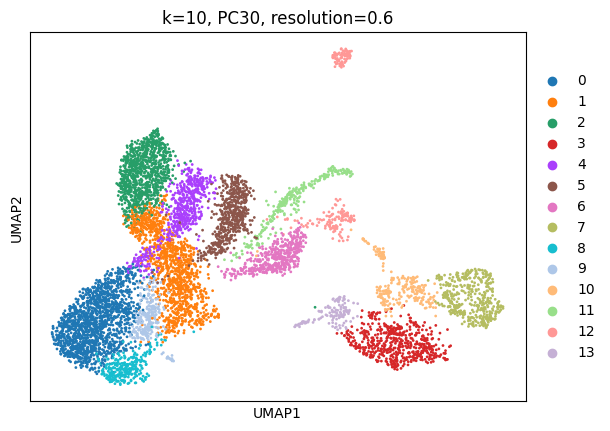

/tmp/ipykernel_1508/3942278130.py:5: UserWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
  sc.tl.leiden(work,resolution=0.6,random_state=SEED,flavor="leidenalg",n_iterations=-1,directed=True,key_added="leiden_k")


/tmp/ipykernel_1508/3942278130.py:9: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.umap(work,color="leiden_k",title=f"k={k}, PC30, resolution=0.6",save=f"_k{k}.png")


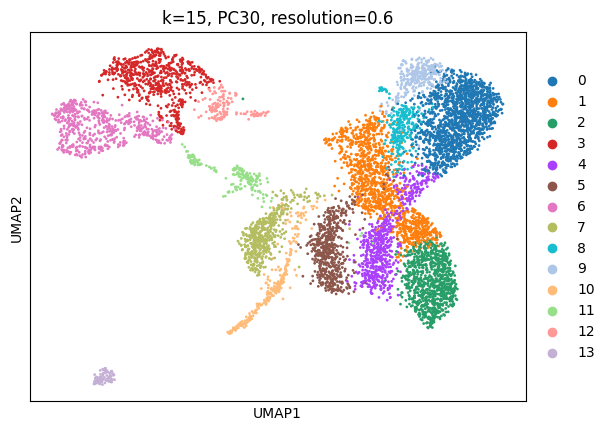

/tmp/ipykernel_1508/3942278130.py:5: UserWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
  sc.tl.leiden(work,resolution=0.6,random_state=SEED,flavor="leidenalg",n_iterations=-1,directed=True,key_added="leiden_k")


/tmp/ipykernel_1508/3942278130.py:9: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.umap(work,color="leiden_k",title=f"k={k}, PC30, resolution=0.6",save=f"_k{k}.png")


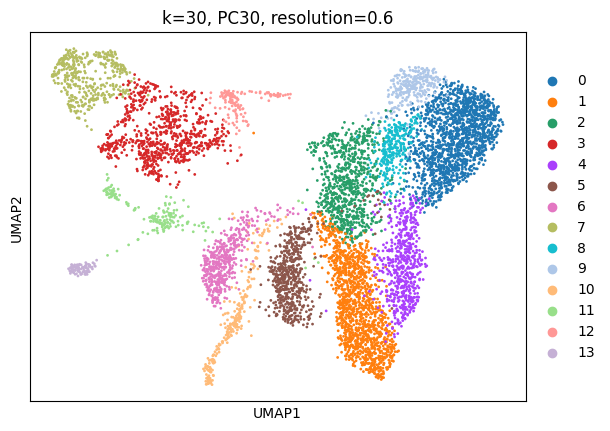

 k  n_clusters  ARI_vs_final_k15
10          14          0.922693
15          14          1.000000
30          14          0.830910


In [ ]:
sensitivity=[]
for k in [10,15,30]:
    work=adata.copy()
    sc.pp.neighbors(work,n_pcs=30,n_neighbors=k,random_state=SEED)
    sc.tl.leiden(work,resolution=0.6,random_state=SEED,flavor="leidenalg",n_iterations=-1,directed=True,key_added="leiden_k")
    sc.tl.umap(work,random_state=SEED)
    sensitivity.append({"k":k,"n_clusters":work.obs["leiden_k"].nunique(),
                        "ARI_vs_final_k15":adjusted_rand_score(adata.obs["leiden_30"],work.obs["leiden_k"])})
    sc.pl.umap(work,color="leiden_k",title=f"k={k}, PC30, resolution=0.6",save=f"_k{k}.png")
pd.DataFrame(sensitivity).to_csv(OUT / "neighbor_sensitivity.csv",index=False)

print(pd.DataFrame(sensitivity).to_string(index=False))


In [ ]:
import scanpy as sc
import pandas as pd

# 각 클러스터의 Marker Gene 분석
sc.tl.rank_genes_groups(
    adata,
    groupby='leiden',
    method='t-test',
    use_raw=False,
    pts=True
)

print("Marker Gene Analysis is done")

Marker Gene Analysis is done


In [ ]:
# 각 클러스터별 상위 7개 Marker Gene 추출

results = []

for cluster in adata.obs['leiden'].cat.categories:

    df = sc.get.rank_genes_groups_df(
        adata,
        group=cluster
    )

    # 유의한 Marker Gene 선정
    df = df[
        (df['pvals_adj'] < 0.05) &
        (df['logfoldchanges'] > 0.25)
    ]

    top_genes = df['names'].head(7).tolist()

    results.append({
        'Cluster': cluster,
        'Top Marker Genes': ', '.join(top_genes)
    })

marker_summary = pd.DataFrame(results)

display(marker_summary)

,Cluster,Top Marker Genes
0,0,"IFITM2, FCGR3A, LST1, IFITM3, FCER1G, LY6E, AIF1"
1,1,"RPS26, HLA-DRB1, CD52, PRELID1, LGALS2, RPS3A, LILRB1"
2,2,"S100A8, S100A9, LYZ, VCAN, RPS26, S100A12, GAPDH"
3,3,"CD74, HLA-DRA, HLA-DRB1, HLA-DPB1, HLA-DMA, IGLV3-1, HLA-DQA1"
4,4,"LYZ, RPL39, S100A8, S100A4, S100A9, S100A6, RPL34"
5,5,"FOS, S100A8, LYZ, IER2, S100A9, CEBPD, DUSP1"
6,6,"IER3, CD83, C1QC, C1QA, C1QB, FOSB, NFKBIA"
7,7,"FOS, LYZ, S100A9, S100A8, DUSP1, KLF6, VCAN"
8,8,"IFITM3, IFITM2, LST1, DUSP1, FCGR3A, RHOB, JUNB"
9,9,"FCGR3A, LST1, LINC01272, RPS19, IFITM2, SERPINA1, LILRB2"


In [ ]:
import re
bad = re.compile(r'^(RPL|RPS|MT-|IGLV|IGKV|IGHV|IGLC|IGKC|FOS|JUN|DUSP1|IER)')
for c in adata.obs['leiden'].cat.categories:
    g = sc.get.rank_genes_groups_df(adata, group=c)['names']
    print(c, [x for x in g if not bad.match(x)][:7])

0 ['IFITM2', 'FCGR3A', 'LST1', 'IFITM3', 'FCER1G', 'LY6E', 'AIF1']
1 ['HLA-DRB1', 'CD52', 'PRELID1', 'LGALS2', 'LILRB1', 'DDIT4', 'KLF2']
2 ['S100A8', 'S100A9', 'LYZ', 'VCAN', 'S100A12', 'GAPDH', 'S100A6']
3 ['CD74', 'HLA-DRA', 'HLA-DRB1', 'HLA-DPB1', 'HLA-DMA', 'HLA-DQA1', 'HLA-DPA1']
4 ['LYZ', 'S100A8', 'S100A4', 'S100A9', 'S100A6', 'FCN1', 'AC090498.1']
5 ['S100A8', 'LYZ', 'S100A9', 'CEBPD', 'EGR1', 'VCAN', 'S100A4']
6 ['CD83', 'C1QC', 'C1QA', 'C1QB', 'NFKBIA', 'CXCL8', 'PPP1R15A']
7 ['LYZ', 'S100A9', 'S100A8', 'KLF6', 'VCAN', 'MCL1', 'FCN1']
8 ['IFITM3', 'IFITM2', 'LST1', 'FCGR3A', 'RHOB', 'KLF2', 'EGR1']
9 ['FCGR3A', 'LST1', 'LINC01272', 'IFITM2', 'SERPINA1', 'LILRB2', 'CORO1A']
10 ['LYZ', 'RETN', 'S100A8', 'S100A9', 'LINC00936', 'KLF6', 'VCAN']
11 ['CD74', 'HLA-DQA1', 'HLA-DPB1', 'HLA-DQB1', 'HLA-DRA', 'HLA-DPA1', 'HLA-DRB1']
12 ['SOD2', 'IL1B', 'SRGN', 'PPP1R15A', 'NFKBIA', 'PLAUR', 'CDKN1A']
13 ['ITM2C', 'JCHAIN', 'PLD4', 'IRF8', 'ALOX5AP', 'IRF7', 'TCF4']


Mono_CD14 available markers: ['FCN1', 'S100A9', 'S100A8']
Mono_CD16 available markers: ['FCGR3A', 'LST1', 'LILRB2']
Mono/Macro available markers: ['CD68', 'CD163']
Macro_C1QC available markers: ['C1QC', 'C1QA', 'APOE']
Macro_NLRP3 available markers: ['NLRP3', 'EREG', 'IL1B']
cDC1 available markers: ['CLEC9A', 'FLT3', 'IDO1']
cDC2 available markers: ['CD1C', 'FCER1A', 'HLA-DQA1']
cDC3_LAMP3 available markers: ['LAMP3', 'CCR7', 'FSCN1']
pDC available markers: ['LILRA4', 'GZMB', 'IL3RA']
Mast available markers: ['KIT']


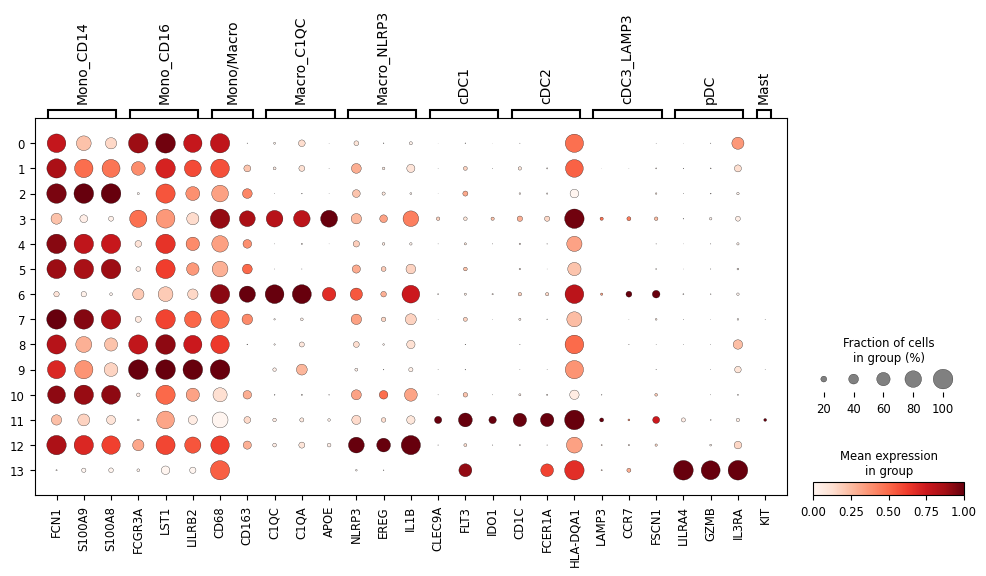

In [ ]:
import scanpy as sc

# 세포 유형별 대표 Marker gene
marker_genes = {
    "Mono_CD14":   ["FCN1", "S100A9", "S100A8"],    # Fig 1E
    "Mono_CD16":   ["FCGR3A", "LST1", "LILRB2"],    # Fig 1E
    "Mono/Macro":  ["CD68", "CD163"],               # Fig 1D
    "Macro_C1QC":  ["C1QC", "C1QA", "APOE"],        # Fig 1E
    "Macro_NLRP3": ["NLRP3", "EREG", "IL1B"],       # Fig 1E
    "cDC1":        ["CLEC9A", "FLT3", "IDO1"],      # Fig 1E
    "cDC2":        ["CD1C", "FCER1A", "HLA-DQA1"],  # Fig 1E, Fig 1D
    "cDC3_LAMP3":  ["LAMP3", "CCR7", "FSCN1"],      # Fig 1E
    "pDC":         ["LILRA4", "GZMB", "IL3RA"],     # Fig 1E, Fig 1D
    "Mast":        ["KIT", "TPSAB1", "CPA3"],       # Fig 1E, Fig 1D
}

tam_subsets = {   # 논문 TAM 아형
    "Macro_SPP1":  ["SPP1"],
    "Macro_C1QC":  ["C1QC"],
    "Macro_ISG15": ["ISG15"],
}

# 1. 데이터셋에 존재하는 유전자만 필터링하여 새로운 딕셔너리 생성
available_markers = {}
for cell_type, genes in marker_genes.items():
    available = [gene for gene in genes if gene in adata.var_names]
    if available:
        available_markers[cell_type] = available
        print(f"{cell_type} available markers: {available}")

# 2. 필터링된 딕셔너리를 통째로 전달하여 하나의 통합된 dotplot 생성
sc.pl.dotplot(
    adata,
    var_names=available_markers,
    groupby="leiden",
    standard_scale="var",
    use_raw=False,
    cmap="Reds" # 이미지와 비슷한 파랑-노랑-빨강 색상 맵 적용
)

In [ ]:
mast = ['KIT', 'TPSAB1', 'TPSB2', 'CPA3', 'MS4A2', 'HDC']
print('데이터에 있는 마스트 유전자:', [g for g in mast if g in adata.var_names])
if 'KIT' in adata.var_names:
    print('KIT 발현 세포 수:', int((adata[:, 'KIT'].X > 0).sum()))
else:
    print('KIT는 입력 행렬에 없습니다.')

데이터에 있는 마스트 유전자: ['KIT']
KIT 발현 세포 수: 16


### 기존 군집 번호 기반 주석표
아래 주석은 기존 해석을 유지한 후보 표입니다. 새 실행의 마커를 확인한 뒤 확정하세요. 추정 샘플을 환자로 간주하지 않으며, DC 세부 유형 및 대식세포 상태를 군집 번호만으로 확정하지 않습니다.

In [ ]:
import pandas as pd

annot_table = pd.DataFrame([
    ['2, 4, 5, 7, 10', 'Mono_CD14',                     'FCN1, S100A9, S100A8'],
    ['0, 8, 9',        'Mono_CD16',                     'FCGR3A, LST1, LILRB2'],
    ['1',              'Mono_CD14CD16 (중간형)',         'CD14·CD16 마커 둘 다 중간'],
    ['6',              'Macro_C1QC',                    'C1QC, C1QA, CD163'],
    ['3',              'Macro_C1QC (APOE 높은 쪽)',      'APOE, CD68, CD163, HLA-DQA1'],
    ['12',             'Macro_NLRP3',                   'NLRP3, EREG, IL1B'],
    ['11',             'cDC 후보 (cDC2/cDC1 다중 마커 검토 필요)',     'CD1C, FCER1A, HLA-DQA1'],
    ['13',             'pDC',                           'LILRA4, GZMB, IL3RA'],
    ['-',              'Mast (없음)',                    'KIT 거의 0'],
], columns=['클러스터', '세포 유형', '가장 진한 마커'])

# 클러스터별 세포 수 합치기
counts = adata.obs['leiden'].value_counts()
annot_table['세포 수'] = annot_table['클러스터'].apply(
    lambda s: sum(counts.get(c.strip(), 0) for c in s.split(',')))

annot_table

,클러스터,세포 유형,가장 진한 마커,세포 수
0,"2, 4, 5, 7, 10",Mono_CD14,"FCN1, S100A9, S100A8",2773
1,"0, 8, 9",Mono_CD16,"FCGR3A, LST1, LILRB2",2081
2,1,Mono_CD14CD16 (중간형),CD14·CD16 마커 둘 다 중간,1188
3,6,Macro_C1QC,"C1QC, C1QA, CD163",545
4,3,Macro_C1QC (APOE 높은 쪽),"APOE, CD68, CD163, HLA-DQA1",640
5,12,Macro_NLRP3,"NLRP3, EREG, IL1B",135
6,11,cDC 후보 (cDC2/cDC1 다중 마커 검토 필요),"CD1C, FCER1A, HLA-DQA1",175
7,13,pDC,"LILRA4, GZMB, IL3RA",82
8,-,Mast (없음),KIT 거의 0,0


## 실행 조건과 결과 저장

In [ ]:
adata.obs.to_csv(OUT / "final_cell_metadata.csv",index_label="cell_barcode")
adata.var.to_csv(OUT / "gene_metadata.csv")
adata.write_h5ad(OUT / "MYE_analysis.h5ad",compression="gzip")
manifest={"input_file":FILE.name,"n_cells":adata.n_obs,"n_genes":adata.n_vars,
          "cell_order_sha256":input_hash,"versions":versions,"seed":SEED,
          "sample_source":"barcode_suffix_unverified","patient_metadata_available":False,
          "normalization_target":10000,"hvg_flavor":"seurat","hvg_n":2000,
          "doublets_removed":False,"additional_QC_filter":False,"batch_correction":False,
          "mapping_rule":"PC30 row modal PC50; ties choose smallest numeric PC50 label"}
(OUT / "run_manifest.json").write_text(json.dumps(manifest,indent=2,ensure_ascii=False))
print("완료:",OUT.resolve())
import shutil
archive=shutil.make_archive("MYE_results","zip",OUT)
print("결과 압축 파일:",archive)


완료: /content/mye_results
결과 압축 파일: /content/MYE_results.zip


In [ ]:
from google.colab import drive
drive.mount('/content/drive')
DATA = '/content/drive/MyDrive/BioAI_Dataset/'
import os; print(os.listdir(DATA))
import os; print(os.listdir('/content/drive/MyDrive/BioAI_Dataset/'))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['GSE154763_UCEC_metadata.csv.gz', 'GSE154763_LYM_normalized_expression.csv.gz', 'GSE154763_THCA_metadata.csv.gz', 'GSE154763_OV-FTC_metadata.csv.gz', 'GSE154763_LYM_metadata.csv.gz', 'GSE154763_MYE_metadata.csv.gz', 'GSE154763_KIDNEY_normalized_expression.csv.gz', 'GSE154763_ESCA_metadata.csv.gz', '.DS_Store', 'GSE154763_PAAD_metadata.csv.gz', 'GSE154763_OV-FTC_normalized_expression.csv.gz', 'GSE154763_MYE_normalized_expression.csv.gz', 'GSE154763_UCEC_normalized_expression.csv.gz', 'GSE154763_PAAD_normalized_expression.csv.gz', 'GSE154763_THCA_normalized_expression.csv.gz', 'GSE154763_ESCA_normalized_expression.csv.gz', 'GSE154763_KIDNEY_metadata.csv.gz']


**8개 암종 인화 데이터 나오면 넣어서 다음 실행**

In [ ]:
cancers = ['ESCA','KIDNEY','LYM','MYE','OV-FTC','PAAD','THCA','UCEC']
list_of_ad = []
for c in cancers:
    X = pd.read_csv(DATA + f'GSE154763_{c}_normalized_expression.csv.gz', index_col=0)
    m = pd.read_csv(DATA + f'GSE154763_{c}_metadata.csv.gz', index_col=0)
    a = sc.AnnData(X.astype('float32')); a.obs = m.reindex(a.obs_names)
    print(c, a.shape, '매칭', a.obs['patient'].notna().sum())
    a.obs_names = c + '_' + a.obs_names
    list_of_ad.append(a)
merged = sc.concat(list_of_ad, join='inner')
merged.write_h5ad('GSE154763_8cancers_merged.h5ad')

In [ ]:
adata = sc.read_h5ad('GSE154763_8cancers_merged.h5ad')
# 1-1 → 1-2 → 1-3 → 1-4 → 4-1 → 4-3 → 4-4 순서로 그대로 다시 실행
# 오염 점검 (정상_악성_구분마커_검토.md 4절 코드)
sc.pl.dotplot(adata, {'골수계': ['PTPRC','CD68','LYZ'], '상피': ['EPCAM','KRT8','KRT18'],
                      'B': ['CD79A','MS4A1'], '형질': ['SDC1','MZB1']}, groupby='cancer', save='_contam.png')

In [ ]:
!pip install -q scanpy bbknn harmonypy leidenalg igraph
import scanpy as sc, pandas as pd, numpy as np, bbknn
from sklearn.metrics import adjusted_rand_score as ari, silhouette_score
from pathlib import Path
sc.settings.figdir = 'figs_1115'

# 파일 체크 및 유동적 업로드 로직 추가
meta_file = Path(DATA + 'GSE154763_MYE_metadata.csv.gz')
if not meta_file.exists():
    try:
        from google.colab import files
        print("GSE154763_MYE_metadata.csv.gz 파일이 존재하지 않습니다. 파일을 업로드해 주세요.")
        uploaded = files.upload()
    except ImportError:
        raise FileNotFoundError("GSE154763_MYE_metadata.csv.gz 파일을 작업 폴더에 직접 업로드하세요.")

adata = sc.read_h5ad('GSE154763_annotated_v1.h5ad')
meta = pd.read_csv(DATA + 'GSE154763_MYE_metadata.csv.gz', index_col=0)    # 11/6에 받은 파일
for c in ['patient', 'tissue', 'MajorCluster', 'cancer']:
    adata.obs[c] = meta.reindex(adata.obs_names)[c].astype(str).values
print(adata.obs['patient'].value_counts())

patient
P20190306    3031
P20190122    2844
P20190322    1384
P20181219     360
Name: count, dtype: int64


In [ ]:
def recipe(ad, method='bbknn', batch='patient', n_pcs=30, res=0.6):
    ad = ad.copy()
    if 'counts' in ad.layers:                                # MYE count 파일로 시험할 때
        ad.X = ad.layers['counts'].copy()
        sc.pp.normalize_total(ad, target_sum=1e4); sc.pp.log1p(ad)
    # GEO normalized_expression은 이미 normalize_total + log 값이라 그대로 씀 (정규화 다시 하면 안 됨)
    sc.pp.highly_variable_genes(ad, n_top_genes=2000, flavor='seurat')
    sc.tl.pca(ad, n_comps=n_pcs, mask_var='highly_variable', random_state=0)
    if method == 'bbknn':
        bbknn.bbknn(ad, batch_key=batch, n_pcs=n_pcs)
    elif method == 'harmony':
        import harmonypy
        Z = harmonypy.run_harmony(ad.obsm['X_pca'], ad.obs, batch, random_state=0).Z_corr
        ad.obsm['X_harmony'] = np.asarray(Z if Z.shape[0] == ad.n_obs else Z.T)   # 버전마다 방향이 달라서 맞춤
        sc.pp.neighbors(ad, use_rep='X_harmony', n_neighbors=15, random_state=0)
    elif method == 'scvi':
        sc.pp.neighbors(ad, use_rep='X_scVI', n_neighbors=15, random_state=0)  # 4-1에서 X_scVI를 먼저 만듦
    else:                                                    # 'none' = 보정 전
        sc.pp.neighbors(ad, n_neighbors=15, n_pcs=n_pcs, random_state=0)
    sc.tl.leiden(ad, resolution=res, random_state=0, flavor='igraph', n_iterations=2, directed=False)
    sc.tl.umap(ad, random_state=0)
    return ad

# 8개 암종을 합칠 때는 합치기 전에 바코드 앞에 암종 이름을 붙임
# ad.obs_names = 'MYE_' + ad.obs_names

/tmp/ipykernel_1508/2089695713.py:8: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.umap(ad, color=['patient','tissue','leiden'], save=f'_{m}_batch.png')


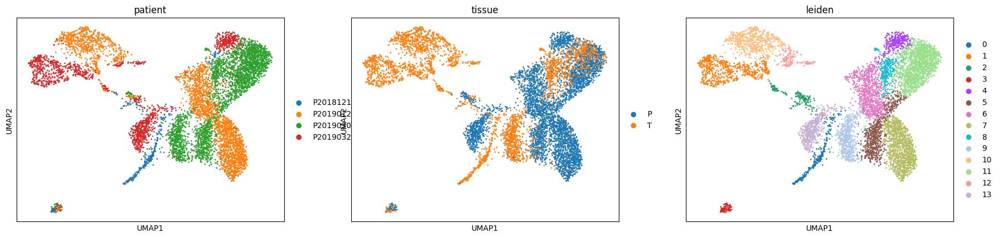

/tmp/ipykernel_1508/2089695713.py:9: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.umap(ad, color=markers, ncols=6, cmap='Reds', vmax='p99', save=f'_{m}_markers.png')


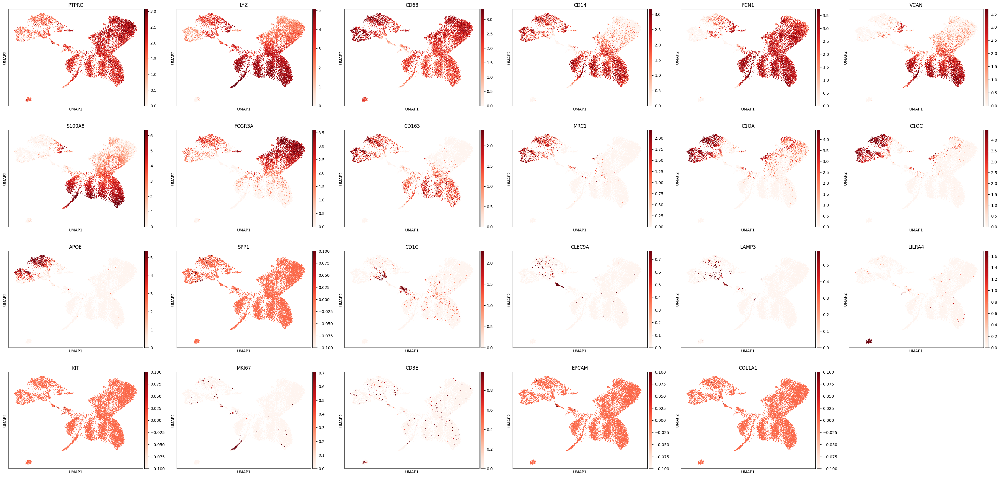

/tmp/ipykernel_1508/2089695713.py:15: Pandas4Warning: Starting with pandas version 4.0 all arguments of max will be keyword-only.
  one = int(((ct.max(1) / ct.sum(1)) > 0.9).sum())
/tmp/ipykernel_1508/2089695713.py:15: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  one = int(((ct.max(1) / ct.sum(1)) > 0.9).sum())


none | 군집 14 | 한 환자 90% 초과 군집 9 / 14 | 환자 silhouette 0.063 | 군집 silhouette 0.126


/tmp/ipykernel_1508/2089695713.py:8: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.umap(ad, color=['patient','tissue','leiden'], save=f'_{m}_batch.png')


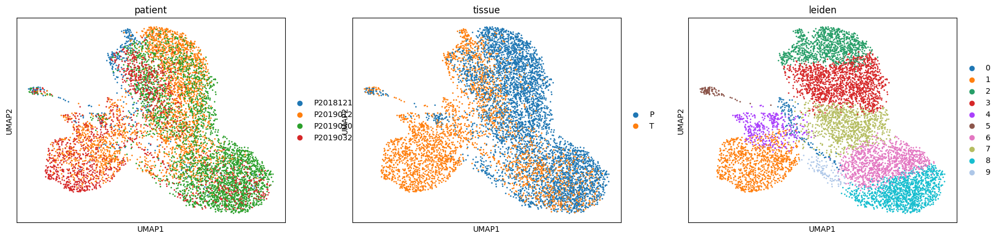

/tmp/ipykernel_1508/2089695713.py:9: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.umap(ad, color=markers, ncols=6, cmap='Reds', vmax='p99', save=f'_{m}_markers.png')


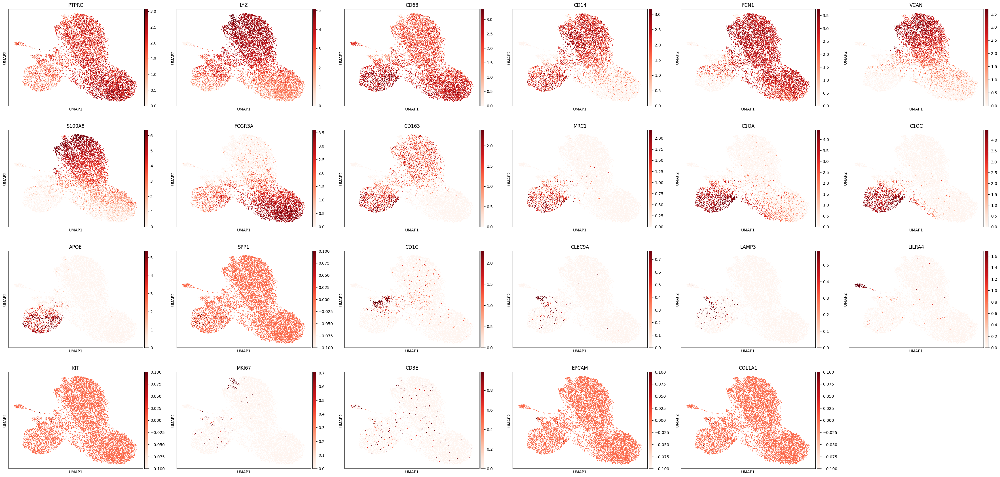

/tmp/ipykernel_1508/2089695713.py:15: Pandas4Warning: Starting with pandas version 4.0 all arguments of max will be keyword-only.
  one = int(((ct.max(1) / ct.sum(1)) > 0.9).sum())
/tmp/ipykernel_1508/2089695713.py:15: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  one = int(((ct.max(1) / ct.sum(1)) > 0.9).sum())


bbknn | 군집 10 | 한 환자 90% 초과 군집 0 / 10 | 환자 silhouette 0.063 | 군집 silhouette 0.113


In [ ]:
markers = ['PTPRC','LYZ','CD68','CD14','FCN1','VCAN','S100A8','FCGR3A','CD163','MRC1',
           'C1QA','C1QC','APOE','SPP1','CD1C','CLEC9A','LAMP3','LILRA4','KIT','MKI67',
           'CD3E','EPCAM','COL1A1']
markers = [g for g in markers if g in adata.var_names]

res = {m: recipe(adata, method=m) for m in ['none', 'bbknn']}
for m, ad in res.items():
    sc.pl.umap(ad, color=['patient','tissue','leiden'], save=f'_{m}_batch.png')
    sc.pl.umap(ad, color=markers, ncols=6, cmap='Reds', vmax='p99', save=f'_{m}_markers.png')

    # pd.crosstab() 대신 Pandas 2.2.3 unstack 버그를 우회하는 groupby 연산 사용
    ct = ad.obs.groupby(['leiden', 'patient'], observed=False).size().unstack(fill_value=0)
    ct.to_csv(f'figs_1115/{m}_cluster_x_patient.csv')

    one = int(((ct.max(1) / ct.sum(1)) > 0.9).sum())
    X = ad.obsm['X_pca'][:, :30]
    print(m, '| 군집', ad.obs['leiden'].nunique(), '| 한 환자 90% 초과 군집', one, '/', len(ct),
          '| 환자 silhouette', round(silhouette_score(X, ad.obs['patient'], sample_size=5000, random_state=0), 3),
          '| 군집 silhouette', round(silhouette_score(X, ad.obs['leiden'], sample_size=5000, random_state=0), 3))

In [ ]:
ad = res['bbknn']
genes = ['CD163', 'C1QC', 'C1QA', 'APOE']
pct = pd.DataFrame({g: pd.Series(ad[:, g].layers['counts'].toarray().ravel() > 0, index=ad.obs_names)
                        .groupby(ad.obs['leiden']).mean() * 100 for g in genes}).round(0)
pct['세포수'] = ad.obs['leiden'].value_counts()
pct['통과'] = (pct[genes] >= 50).all(axis=1)
print(pct)
keep = pct.index[pct['통과']]

# pd.crosstab() 대신 Pandas 2.2.3 unstack 버그를 완전히 우회하는 groupby 연산 사용
cross_tab = ad.obs.groupby([ad.obs['leiden'].isin(keep), ad.obs['MajorCluster']], observed=False).size().unstack(fill_value=0)
print(cross_tab)   # 저자 라벨과 일치도

        CD163  C1QC   C1QA  APOE   세포수     통과
leiden                                       
0        27.0  11.0   20.0  10.0   127  False
1        82.0  91.0   91.0  77.0   969   True
2        34.0   0.0    1.0   0.0  1014  False
3        44.0   0.0    2.0   0.0  1597  False
4        39.0  42.0   47.0  31.0   398  False
5         0.0   0.0    0.0   0.0    89  False
6         2.0   2.0   19.0   0.0  1097  False
7        30.0   3.0   12.0   0.0   954  False
8         0.0   5.0   29.0   0.0  1274  False
9         5.0  95.0  100.0   0.0   100  False
MajorCluster  M01_pDC_LILRA4  M02_cDC1_CLEC9A  M03_cDC2_CD1C  M04_cDC3_LAMP3  M05_Mono_CD14  M06_Mono_CD14CD16  M07_Mono_CD16  \
leiden                                                                                                                          
False                     89               41            283               6           2287               1544           2082   
True                       0                1             31 

군집 1이 C1QC 대식세포인 이유: 네 유전자가 모두 대식세포 표지라서, 네 개를 다 켠 세포가 80% 넘게 모인 곳이면 대식세포 덩어리로 보는 게 자연스러움.
187개를 놓친 이유: 기준이 "네 유전자 모두 50% 이상"이라서, 하나라도 50%에 못 미치는 군집(군집 4처럼 40%대)은 통째로 빠짐.
군집 5가 pDC인 이유: pDC는 대식세포 유전자를 거의 안 켜서 0%가 나오고, 세포 수(89)도 저자 pDC 수와 똑같음.

res 0.4 vs 0.6 ARI 0.438


/tmp/ipykernel_1508/3665217948.py:13: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.rank_genes_groups_dotplot(mac, n_genes=5, key='rank_genes_groups_filtered', save='_mac_markers.png')


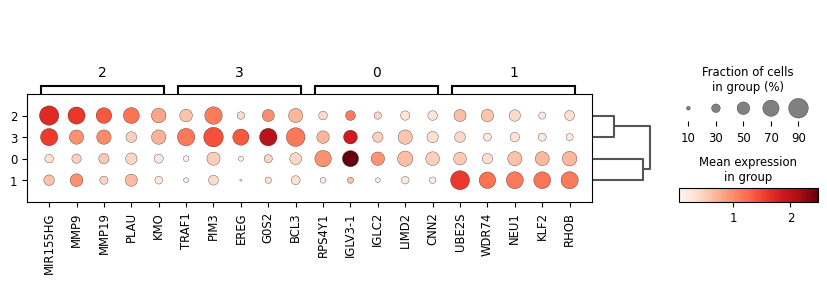

/tmp/ipykernel_1508/3665217948.py:19: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.dotplot(mac, available_check_genes,


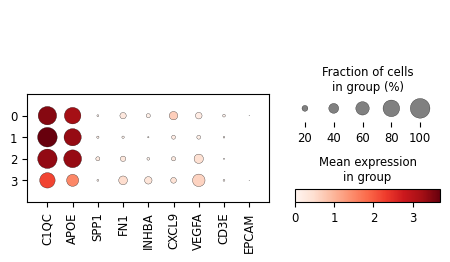

In [ ]:
mac = ad[ad.obs['leiden'].isin(keep)].copy()
# mac.X는 이미 log 정규화 값이라 정규화 다시 안 함
sc.pp.highly_variable_genes(mac, n_top_genes=2000, flavor='seurat')
sc.tl.pca(mac, n_comps=30, random_state=0)
bbknn.bbknn(mac, batch_key='patient', n_pcs=15, neighbors_within_batch=3)   # PC 15 = Hu 2023
for r in [0.4, 0.6]:
    sc.tl.leiden(mac, resolution=r, random_state=0, key_added=f'mac_r{r}', flavor='igraph', n_iterations=2, directed=False)
sc.tl.umap(mac, random_state=0)
print('res 0.4 vs 0.6 ARI', round(ari(mac.obs['mac_r0.4'], mac.obs['mac_r0.6']), 3))

sc.tl.rank_genes_groups(mac, 'mac_r0.4', method='wilcoxon')
sc.tl.filter_rank_genes_groups(mac, min_in_group_fraction=0.25)
sc.pl.rank_genes_groups_dotplot(mac, n_genes=5, key='rank_genes_groups_filtered', save='_mac_markers.png')

# 데이터셋에 실제로 존재하는 마커 유전자만 필터링하여 에러 방지
check_genes = ['C1QC','APOE','SPP1','FN1','INHBA','CXCL9','SELENOP','FABP4','VEGFA','CD3E','EPCAM']
available_check_genes = [g for g in check_genes if g in mac.var_names]

sc.pl.dotplot(mac, available_check_genes,
              groupby='mac_r0.4', save='_mac_check.png')       # CD3E·EPCAM 켜진 군집 = 이중 계통 후보

ARI 0.438은 대식세포 안의 세부 군집은 해상도(res)에 따라 꽤 바뀐다는 뜻임. 이유는 세부 상태끼리 차이가 작아서 경계가 흐리기 때문임. 그래서 세부 상태는 "후보"로만 쓰고 단정하지 않는 게 맞음.

res 0.4에서 세부 상태 4개, res 0.6과의 ARI는 0.466이었음. 세포 1,142개라 해상도에 따라 많이 흔들림. 그래서 MYE만으로는 세부 상태를 확정하지 않고, 8개 암종 합친 뒤 다시 봄.

In [ ]:
!pip install -q scvi-tools        # 설치 후 런타임 다시 시작 → 0번 셀부터 다시
import scvi; scvi.settings.seed = 0
tmp = adata.copy()
scvi.model.SCVI.setup_anndata(tmp, layer='counts', batch_key='patient')
m = scvi.model.SCVI(tmp, n_latent=30)
m.train(accelerator='gpu')
adata.obsm['X_scVI'] = m.get_latent_representation()
print('scvi', scvi.__version__)

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


INFO: Seed set to 0
INFO:lightning.fabric.utilities.seed:Seed set to 0
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
/usr/local/lib/python3.13/dist-

Training:   0%|          | 0/400 [00:00<?, ?it/s]

INFO: `Trainer.fit` stopped: `max_epochs=400` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=400` reached.


scvi 1.5.2


2026-11-13 11:01:03,251 - harmonypy - INFO - Running Harmony
INFO:harmonypy:Running Harmony
2026-11-13 11:01:03,255 - harmonypy - INFO -   Parameters:
INFO:harmonypy:  Parameters:
2026-11-13 11:01:03,258 - harmonypy - INFO -     max_iter_harmony: 10
INFO:harmonypy:    max_iter_harmony: 10
2026-11-13 11:01:03,264 - harmonypy - INFO -     max_iter_kmeans: 4
INFO:harmonypy:    max_iter_kmeans: 4
2026-11-13 11:01:03,267 - harmonypy - INFO -     epsilon_cluster: 0.001
INFO:harmonypy:    epsilon_cluster: 0.001
2026-11-13 11:01:03,273 - harmonypy - INFO -     epsilon_harmony: 0.01
INFO:harmonypy:    epsilon_harmony: 0.01
2026-11-13 11:01:03,277 - harmonypy - INFO -     nclust: 100
INFO:harmonypy:    nclust: 100
2026-11-13 11:01:03,282 - harmonypy - INFO -     block_size: 0.05
INFO:harmonypy:    block_size: 0.05
2026-11-13 11:01:03,288 - harmonypy - INFO -     lamb: dynamic (alpha=0.2)
INFO:harmonypy:    lamb: dynamic (alpha=0.2)
2026-11-13 11:01:03,292 - harmonypy - INFO -     theta: [2. 2. 2

/tmp/ipykernel_1508/931310895.py:15: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.umap(ad, color=['patient','tissue'] + ['CD14','FCGR3A','C1QC','CD1C','CLEC9A','LILRA4'],


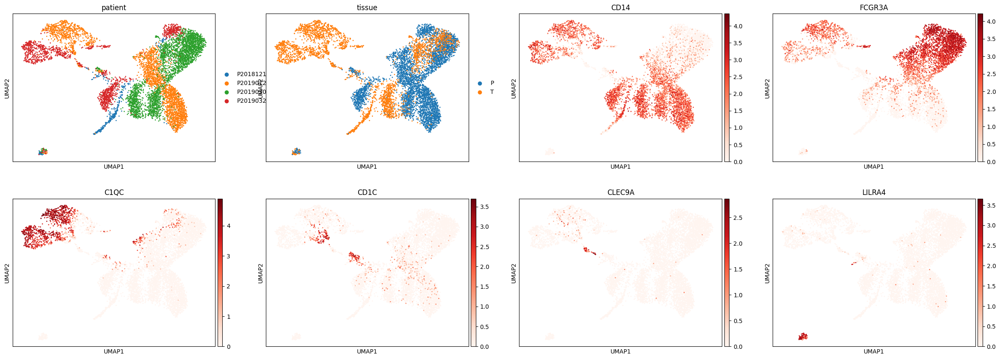

/tmp/ipykernel_1508/931310895.py:15: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.umap(ad, color=['patient','tissue'] + ['CD14','FCGR3A','C1QC','CD1C','CLEC9A','LILRA4'],


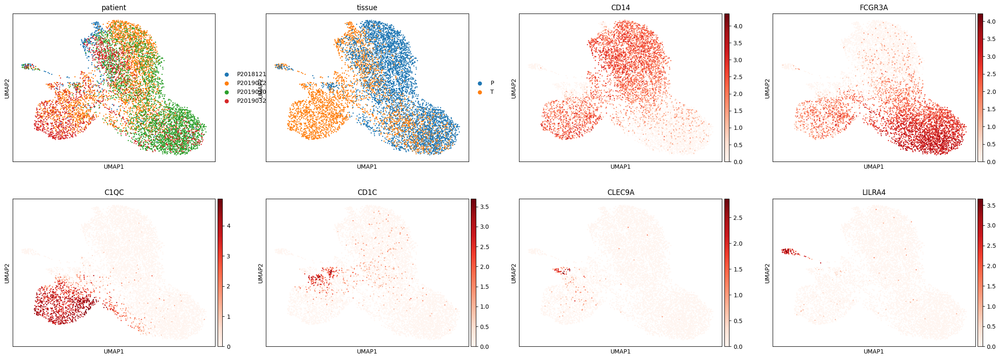

/tmp/ipykernel_1508/931310895.py:15: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.umap(ad, color=['patient','tissue'] + ['CD14','FCGR3A','C1QC','CD1C','CLEC9A','LILRA4'],


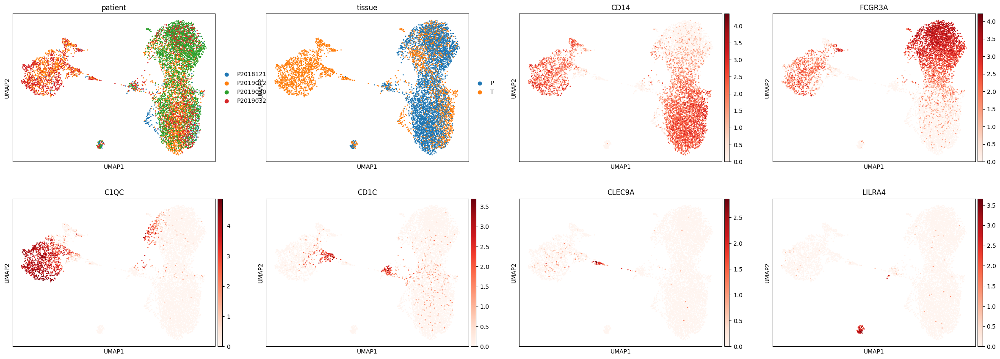

/tmp/ipykernel_1508/931310895.py:15: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.umap(ad, color=['patient','tissue'] + ['CD14','FCGR3A','C1QC','CD1C','CLEC9A','LILRA4'],


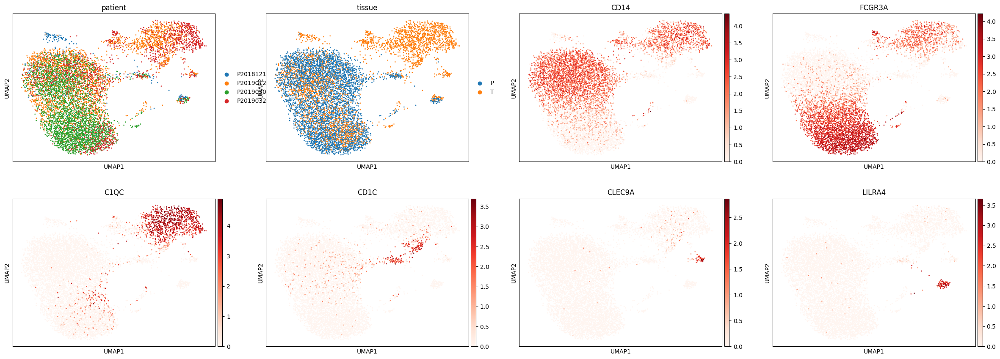

        방법  군집 수  한 환자 90% 초과 군집  환자 silhouette  군집 silhouette  보정 전과 ARI
0     none    14               9          0.063          0.126      1.000
1    bbknn    10               0          0.063          0.113      0.357
2  harmony    11               1          0.000          0.155      0.411
3     scvi     7               0         -0.005          0.069      0.336
BBKNN vs Harmony ARI 0.508


In [ ]:
for mth in ['harmony', 'scvi']:
    res[mth] = recipe(adata, method=mth)

rows = []
for mth, ad in res.items():
    rep = {'harmony': 'X_harmony', 'scvi': 'X_scVI'}.get(mth, 'X_pca')
    X = ad.obsm[rep][:, :30]
    # Pandas 2.2.3의 unstack 버그를 완전히 우회하는 groupby 연산 사용
    ct = ad.obs.groupby(['leiden', 'patient'], observed=False).size().unstack(fill_value=0)
    rows.append({'방법': mth, '군집 수': ad.obs['leiden'].nunique(),
                 '한 환자 90% 초과 군집': int(((ct.max(axis=1) / ct.sum(axis=1)) > 0.9).sum()),
                 '환자 silhouette': round(silhouette_score(X, ad.obs['patient'], sample_size=5000, random_state=0), 3),
                 '군집 silhouette': round(silhouette_score(X, ad.obs['leiden'], sample_size=5000, random_state=0), 3),
                 '보정 전과 ARI': round(ari(res['none'].obs['leiden'], ad.obs['leiden']), 3)})
    sc.pl.umap(ad, color=['patient','tissue'] + ['CD14','FCGR3A','C1QC','CD1C','CLEC9A','LILRA4'],
               ncols=4, cmap='Reds', save=f'_{mth}_compare.png')
tab = pd.DataFrame(rows); tab.to_csv('figs_1115/method_compare.csv', index=False); print(tab)
print('BBKNN vs Harmony ARI', round(ari(res['bbknn'].obs['leiden'], res['harmony'].obs['leiden']), 3))

BBKNN: 바꾸는 건 "이웃 그래프"임. 이웃을 찾을 때 환자마다 똑같은 수만큼 이웃을 뽑음. PCA 좌표는 그대로라 가장 빠르고 단순함. 논문이 쓴 방법임(Polański 2020).

Harmony: 바꾸는 건 “PCA 좌표”임. 세포를 대략 군집으로 묶은 뒤, 군집마다 환자 간 중심을 맞추도록 좌표를 반복해서 옮김. 보정 결과가 좌표로 남아서 다른 분석에도 쓸 수 있음(Korsunsky 2019).

scVI: 바꾸는 건 "새 좌표 공간"임. 딥러닝(VAE)이 raw count로 배치 효과를 뺀 잠재 공간을 학습함. 가장 유연하지만 GPU가 필요하고 raw count가 필요함(Lopez 2018). 그래서 우리 데이터에선 MYE만 가능함.

환자 섞임: BBKNN과 scVI는 한 환자 쏠림 군집이 0개, Harmony는 1개임. 셋 다 보정 전(9개)보다 크게 좋아졌음.

scVI 주의: 환자 silhouette가 -0.005로 가장 많이 섞였는데, 군집 silhouette도 0.069로 가장 낮고 군집 수도 7개로 가장 적음. 세포형끼리 합쳐졌을 수 있으니(과보정) 4-2 확인표에서 pDC, cDC1이 따로 남았는지 꼭 볼 것.

방법 간 일치: BBKNN과 Harmony의 ARI는 0.508로 중간 정도임(가이드에선 0.698). 큰 세포형은 비슷하게 잡지만 세부 군집 경계는 방법마다 다르다는 뜻임.

silhouette은 방법마다 계산한 공간(PCA, Harmony, scVI)이 달라서 숫자를 직접 비교하는 건 참고용으로만 써야 함.

In [ ]:
def rare_check(ad):
    out = {}
    for g in ['LILRA4', 'CLEC9A']:     # pDC, cDC1
        x = pd.Series(ad[:, g].layers['counts'].toarray().ravel() > 0, index=ad.obs_names)
        top = x.groupby(ad.obs['leiden']).mean().idxmax()
        out[g] = f"군집 {top}: {int(x[ad.obs['leiden'] == top].sum())}개 양성 / 군집 크기 {int((ad.obs['leiden'] == top).sum())}"
    return out
for mth, ad in res.items(): print(mth, rare_check(ad))

none {'LILRA4': '군집 3: 82개 양성 / 군집 크기 82', 'CLEC9A': '군집 2: 46개 양성 / 군집 크기 175'}
bbknn {'LILRA4': '군집 5: 87개 양성 / 군집 크기 89', 'CLEC9A': '군집 4: 78개 양성 / 군집 크기 398'}
harmony {'LILRA4': '군집 6: 82개 양성 / 군집 크기 82', 'CLEC9A': '군집 5: 46개 양성 / 군집 크기 156'}
scvi {'LILRA4': '군집 4: 85개 양성 / 군집 크기 116', 'CLEC9A': '군집 3: 49개 양성 / 군집 크기 228'}


pDC(LILRA4)

보정 전과 Harmony: 82/82로 순수한 pDC 군집이 그대로 남았음.
BBKNN: 87/89로 거의 순수함.
scVI: 85/116이라 다른 세포 31개가 섞였음. 아까 말한 과보정 신호와 맞아떨어짐.

cDC1(CLEC9A)

네 방법 모두 cDC1이 따로 떨어지지 않고 DC 군집 안에 섞였음. 해상도 0.6에서는 원래 그런 거라 방법 탓은 아님.
그래도 BBKNN은 78/398로 군집이 가장 커서 가장 많이 희석됐음. 이 군집 4는 아까 C1QC 42%였던 경계 군집이라, DC와 대식세포 일부가 같이 묶였을 가능성이 있음(추정).

결론: 희귀 세포 보존은 Harmony ≥ 보정 전 > BBKNN > scVI 순임. 보고서에는 “scVI는 섞임이 가장 강했지만 pDC가 희석되어 과보정 경향을 보였다”로 쓰면 됨.

In [ ]:
# xtab 대신 Pandas 2.2.3 버그를 안전하게 우회하는 groupby 연산 적용
ct = mac.obs.groupby(['patient', 'mac_r0.4'], observed=False).size().unstack(fill_value=0)
ct = ct[ct.sum(axis=1) >= 10]                                  # 대식세포 10개 미만 환자 제외 (Hu 2023 6쪽)
frac = (ct.div(ct.sum(axis=1), axis=0) * 100).round(1)
frac.to_csv('figs_1115/patient_x_substate.csv'); print(frac)
n_rep = (frac >= 5).sum(axis=0)                               # 5% 이상인 환자 수
print('2명 이상에서 5% 넘는 세부 상태:', int((n_rep >= 2).sum()), '/', frac.shape[1])

mac_r0.4      0     1     2     3
patient                          
P20181219  91.7   8.3   0.0   0.0
P20190122  53.1  13.5   9.9  23.5
P20190322  17.5  50.5  15.9  16.1
2명 이상에서 5% 넘는 세부 상태: 4 / 4


4개 상태는 C1QC+ 대식세포(969개)만 따로 떼서 다시 군집화(res 0.4)했더니 4개 무리로 나뉘었다는 뜻임. 0, 1, 2, 3은 이름이 아니라 번호일 뿐임. 대식세포 안에서도 발현 패턴이 조금씩 다른 하위 상태가 있을 수 있다는 것이고, Q1(C1QC+ 내부 이질성)이 바로 이걸 묻는 질문임.

각 상태가 생물학적으로 뭔지는 아직 모름. 그건 저장된 figs_1115/dotplot__mac_markers.png(상태별 상위 마커 5개)를 봐야 정할 수 있음. 예를 들어 어떤 상태에서 APOE와 C1Q가 높으면 고전적 TAM이고, IL1B나 CXCL8이 높으면 염증성, SPP1이나 VEGFA면 혈관신생 쪽으로 이름을 붙임.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, confusion_matrix
b = res['none'] #8개 암종을 합친 뒤에 y를 cancer로 바꾸면 그게 진짜 Q1 결과
X, y = b.obsm['X_pca'][:, :30], b.obs['tissue'].values          # 합친 뒤: b.obs['cancer'].values
out = []
for p in b.obs['patient'].unique():                               # 환자 하나씩 빼고 평가 (환자 단위 분할)
    tr = b.obs['patient'].values != p; te = ~tr
    clf = LogisticRegression(max_iter=2000).fit(X[tr], y[tr])
    pred = clf.predict(X[te])
    out.append({'평가 환자': p, '세포': int(te.sum()), 'macro F1': round(f1_score(y[te], pred, average='macro'), 3)})
print(pd.DataFrame(out))

       평가 환자    세포  macro F1
0  P20181219   360     0.429
1  P20190122  2844     0.878
2  P20190306  3031     0.585
3  P20190322  1384     0.601


**8개 암종을 합친 뒤에 y를 cancer로 바꾸면 그게 진짜 Q1 결과**

PCA 30개 + LogisticRegression — 세포의 PCA 값을 보고 "어느 암종(지금은 조직) 세포인지" 맞히는 가장 단순한 선형 모델

환자 하나씩 빼고 평가 — 학습에 안 쓴 환자로만 시험 / 같은 환자 세포가 학습·시험에 다 있으면 "환자를 외운 것"일 수 있음

· macro F1 — 클래스마다 F1(정밀도와 재현율의 조화평균)을 따로 구해 단순 평균 / 세포 수가 적은 암종도 똑같이 반영됨. accuracy는 큰 암종이 점수를 끌어올림

P20181219는 0.429로 낮은데, 종양 샘플만 있는 환자라 한 종류만 맞히는 셈이어서 macro F1이 낮게 나오는 것임.

나머지는 0.58~0.88이라, 처음 보는 환자에서도 조직을 어느 정도 구분한다는 뜻임.

In [ ]:
import shutil
shutil.make_archive('/content/drive/MyDrive/BioAI_Dataset/figs_1115', 'zip', 'figs_1115')
print('저장 완료')

저장 완료


**8개 암종 추후 테스트**

In [ ]:
!pip install -q bbknn harmonypy leidenalg igraph
from google.colab import drive; drive.mount('/content/drive')
import scanpy as sc, pandas as pd, numpy as np, scipy.sparse as sp, gc
DATA = '/content/drive/MyDrive/BioAI_Dataset/'
CANCERS = ['ESCA', 'KIDNEY', 'LYM', 'MYE', 'OV-FTC', 'PAAD', 'THCA', 'UCEC']
import os; print(sorted(f for f in os.listdir(DATA) if f.startswith('GSE154763')))   # 16개 보이는지

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['GSE154763_ESCA_metadata.csv.gz', 'GSE154763_ESCA_normalized_expression.csv.gz', 'GSE154763_KIDNEY_metadata.csv.gz', 'GSE154763_KIDNEY_normalized_expression.csv.gz', 'GSE154763_LYM_metadata.csv.gz', 'GSE154763_LYM_normalized_expression.csv.gz', 'GSE154763_MYE_metadata.csv.gz', 'GSE154763_MYE_normalized_expression.csv.gz', 'GSE154763_OV-FTC_metadata.csv.gz', 'GSE154763_OV-FTC_normalized_expression.csv.gz', 'GSE154763_PAAD_metadata.csv.gz', 'GSE154763_PAAD_normalized_expression.csv.gz', 'GSE154763_THCA_metadata.csv.gz', 'GSE154763_THCA_normalized_expression.csv.gz', 'GSE154763_UCEC_metadata.csv.gz', 'GSE154763_UCEC_normalized_expression.csv.gz']
